---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group XX

- Nathanael Shane Bennet (13524119)
- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [2]:
%pip install gdown imbalanced-learn matplotlib numpy pandas scikit-learn

## Import Libraries

Every import of the notebook is kept in this cell.

In [3]:
from __future__ import annotations

import os
import random
import math
import inspect
import operator
import warnings
from pathlib import Path
from numbers import Integral, Real
from statistics import NormalDist
from typing import Any, Dict, List, Optional, Sequence, Tuple

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

## Settings

Paths and shared constants are kept in this class.

In [63]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')
    ID_COLUMN = 'id'
    TARGET = 'is_canceled'
    TEST_SIZE = 0.2
    N_FOLDS = 5
    SUPPORTED_KNN_METRICS = ("minkowski", "euclidean", "manhattan", "chebyshev", "cosine")
    CHUNK_ELEMS = 1 << 21  # cap temporary buffers at ~16 MB of float64 per block
    EPS = 1e-12
    URLS = {
        'train': 'https://drive.google.com/uc?id=1_6x5b1OW6rw5RunfG4uog80j9-SiKcmT',
        'test': 'https://drive.google.com/uc?id=13iP5OnVSPVDlkIBWlTT9oINtVZnCv9oz',
        #'sample_submission': '',
    }

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class ConvergenceWarning(UserWarning):
    """Raised-analog of sklearn's ConvergenceWarning (no sklearn import needed)."""

def _sigmoid(m):
    out = np.empty_like(m, dtype=np.float64)
    pos = m >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-m[pos]))
    em = np.exp(m[~pos])
    out[~pos] = em / (1.0 + em)
    return out

def _numeric_matrix(X):
    """DataFrame/ndarray -> float64 matrix (+ column names or None)."""
    if pd is not None and isinstance(X, pd.DataFrame):
        names = [str(c) for c in X.columns]
        try:
            arr = np.asarray(X.to_numpy(dtype=np.float64), dtype=np.float64)
        except (TypeError, ValueError) as exc:
            raise ValueError("X contains non-numeric data; encode categorical "
                             "features first (e.g. pd.get_dummies or OneHotEncoder).") from exc
        return arr, names
    try:
        arr = np.asarray(X, dtype=np.float64)
    except (TypeError, ValueError) as exc:
        raise ValueError("X must be numeric; encode categorical features first "
                         "(e.g. pd.get_dummies or OneHotEncoder).") from exc
    return arr, None

## Seed Everything

A fixed seed keeps the results reproducible.

In [5]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [6]:
Settings.DATA_DIR.mkdir(parents=True, exist_ok=True)

for name, url in Settings.URLS.items():
    if not url:
        continue

    path = Settings.DATA_DIR / f'{name}.csv'

    if not path.exists():
        gdown.download(url, str(path), quiet=True)

sorted(path.name for path in Settings.DATA_DIR.glob('*.csv'))

['test.csv', 'train.csv']

In [7]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [8]:
train_df

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27368,60213561,2.0,0.0,2,0,Room Only,0.0,Type B,2.0,2024,8,27,Online Travel Agent,0,0,0,1429000.0,0.0,0
27369,15354b3d,2.0,0.0,2,2,Room Only,0.0,Type B,NaN,2024,12,22,Online Travel Agent,0,0,0,1205000.0,1.0,1
27370,530d530c,2.0,0.0,0,2,Breakfast,0.0,Type C,115.0,2024,4,28,Online Travel Agent,0,0,0,1795000.0,0.0,1
27371,1d5d9c6a,2.0,NaN,0,1,Breakfast,0.0,Type B,58.0,2024,4,5,Offline Agent,0,0,0,1305000.0,0.0,0


In [9]:
test_df

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,5cb6f473,2.0,0.0,0,1,Breakfast,0.0,Type B,217.0,2024,8,11,Offline Agent,0,0,0,1299000.0,0.0
1,c06b4ab3,2.0,0.0,1,2,Breakfast,0.0,Type B,190.0,2024,6,19,Online Travel Agent,0,0,0,2010000.0,0.0
2,22bf3fc3,2.0,0.0,1,2,Breakfast,0.0,Type B,124.0,2024,5,12,Online Travel Agent,0,0,0,1921000.0,1.0
3,25408a48,NaN,0.0,2,4,Half Board,0.0,Type B,0.0,2024,1,2,Online Travel Agent,0,0,0,1451000.0,0.0
4,621586b6,2.0,1.0,2,3,Breakfast,0.0,Type G,44.0,2023,11,1,Offline Agent,0,0,0,1225000.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6839,10eeb208,2.0,NaN,2,2,Breakfast,0.0,Type G,1.0,2024,12,22,Online Travel Agent,0,0,0,1572000.0,2.0
6840,3b8dae15,2.0,0.0,0,1,NaN,0.0,Type B,89.0,2024,11,10,Offline Agent,0,0,0,NaN,NaN
6841,2a8e7933,2.0,0.0,1,3,Breakfast,0.0,NaN,74.0,2024,4,24,Online Travel Agent,0,0,0,1687000.0,1.0
6842,1f36b4de,1.0,0.0,2,1,Breakfast,0.0,Type B,1.0,2024,11,26,Online Travel Agent,0,0,0,1146000.0,1.0


In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null  int64  
 14  prior_

In [11]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6844 entries, 0 to 6843
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        6844 non-null   object 
 1   num_adults                6664 non-null   float64
 2   num_children              6097 non-null   float64
 3   weekend_nights            6844 non-null   int64  
 4   weekday_nights            6844 non-null   int64  
 5   meal_package              6402 non-null   object 
 6   needs_parking             6597 non-null   float64
 7   room_category             6602 non-null   object 
 8   days_before_arrival       6554 non-null   float64
 9   arrival_year              6844 non-null   int64  
 10  arrival_month             6844 non-null   int64  
 11  arrival_day               6844 non-null   int64  
 12  booking_channel           6844 non-null   object 
 13  is_returning_guest        6844 non-null   int64  
 14  prior_ca

In [12]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]

    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [13]:
types(train_df)

,dtype,kind,unique
id,object,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,object,categorical,4
needs_parking,float64,numeric,2
room_category,object,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


In [14]:
types(test_df)

,dtype,kind,unique
id,object,categorical,6844
num_adults,float64,numeric,5
num_children,float64,numeric,4
weekend_nights,int64,numeric,7
weekday_nights,int64,numeric,17
meal_package,object,categorical,4
needs_parking,float64,numeric,2
room_category,object,categorical,6
days_before_arrival,float64,numeric,370
arrival_year,int64,numeric,2


## Explore Data

This part covers distributions and relationships between attributes.

In [15]:
def pie(df, column=Settings.TARGET):
    df[column].value_counts().plot.pie(autopct='%.1f%%', ylabel='')
    plt.show()

def bar(df, column=Settings.TARGET):
    df[column].value_counts().plot.bar()
    plt.show()

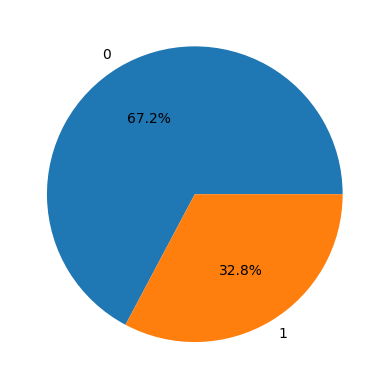

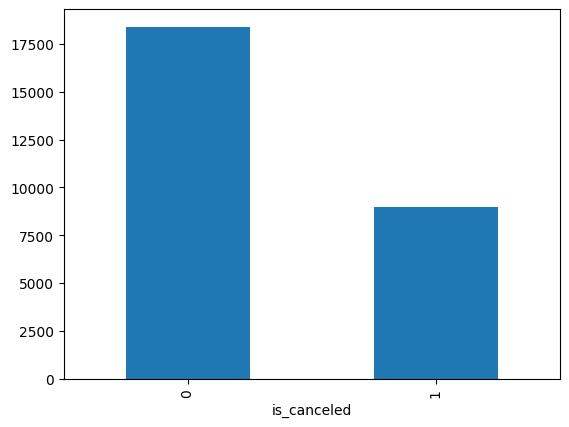

In [16]:
# Plot the target distribution only for the training set
pie(train_df)
bar(train_df)

In [17]:
feature_cols = [col for col in train_df.columns if col not in [CFG.ID_COLUMN, CFG.TARGET]]

num_cols = [col for col in feature_cols if pd.api.types.is_numeric_dtype(train_df[col])]
cat_cols = [col for col in feature_cols if not pd.api.types.is_numeric_dtype(train_df[col])]

num_col_df = train_df[num_cols]
cat_col_df = train_df[cat_cols]

print("Numerical Columns:", list(num_col_df.columns))
print("Categorical Columns:", list(cat_col_df.columns))

Numerical Columns: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Categorical Columns: ['meal_package', 'room_category', 'booking_channel']


In [18]:
num_col_df

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,2.0,NaN,1,2,0.0,88.0,2024,4,3,0,0,0,1330000.0,0.0
1,2.0,0.0,2,1,0.0,120.0,2023,8,1,0,0,0,NaN,0.0
2,3.0,0.0,1,2,0.0,209.0,2024,8,28,0,0,0,2099000.0,0.0
3,2.0,1.0,2,1,0.0,93.0,2024,8,13,0,0,0,1693000.0,2.0
4,2.0,0.0,0,1,0.0,14.0,2024,9,1,0,0,0,2010000.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27368,2.0,0.0,2,0,0.0,2.0,2024,8,27,0,0,0,1429000.0,0.0
27369,2.0,0.0,2,2,0.0,NaN,2024,12,22,0,0,0,1205000.0,1.0
27370,2.0,0.0,0,2,0.0,115.0,2024,4,28,0,0,0,1795000.0,0.0
27371,2.0,NaN,0,1,0.0,58.0,2024,4,5,0,0,0,1305000.0,0.0


In [19]:
cat_col_df

,meal_package,room_category,booking_channel
0,Breakfast,Type B,Offline Agent
1,Half Board,Type D,Offline Agent
2,Breakfast,Type G,Online Travel Agent
3,Breakfast,Type G,Online Travel Agent
4,Room Only,Type B,Online Travel Agent
...,...,...,...
27368,Room Only,Type B,Online Travel Agent
27369,Room Only,Type B,Online Travel Agent
27370,Breakfast,Type C,Online Travel Agent
27371,Breakfast,Type B,Offline Agent


In [20]:
def as_list(columns):
    return [columns] if isinstance(columns, str) else list(columns)

def make_axes(count, ncols=3):
    nrows = -(-count // ncols)
    figure, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)

    for axis in axes.flat[count:]:
        axis.axis('off')

    return axes.flat[:count]

def histogram(columns, by=None, bins=30, data=None):
    frame = train_df if data is None else data

    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        edges = np.histogram_bin_edges(frame[column].dropna(), bins=bins)

        if by is None:
            axis.hist(frame[column].dropna(), bins=edges)
        else:
            for label, group in frame.groupby(by):
                axis.hist(group[column].dropna(), bins=edges, alpha=0.5, label=str(label))

            axis.legend(title=by)

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

def boxplot(columns, by=None, data=None):
    frame = train_df if data is None else data

    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        if by is None:
            axis.boxplot(frame[column].dropna())
            axis.set_xticks([])
        else:
            groups = list(frame.groupby(by)[column])
            axis.boxplot([values.dropna() for _, values in groups])
            axis.set_xticks(range(1, len(groups) + 1), [str(label) for label, _ in groups])

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

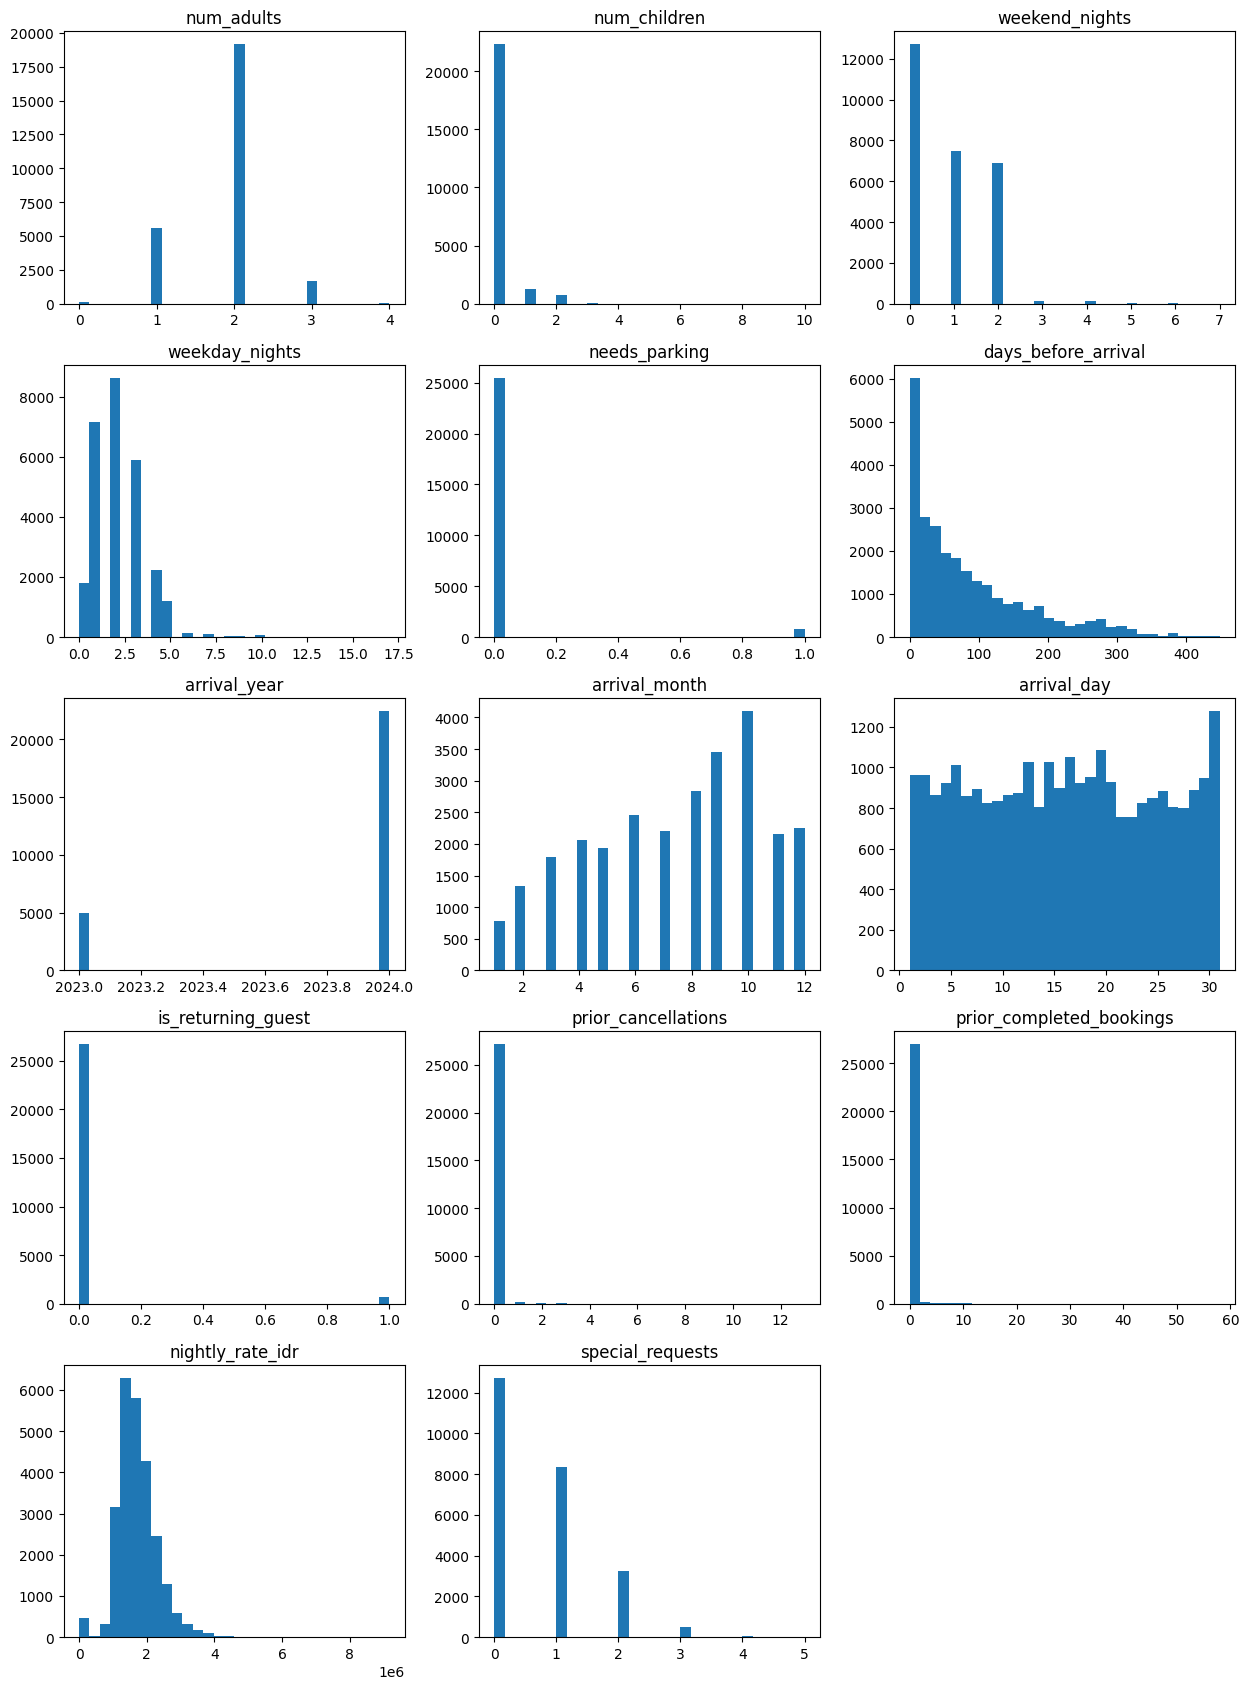

In [21]:
histogram(num_col_df)

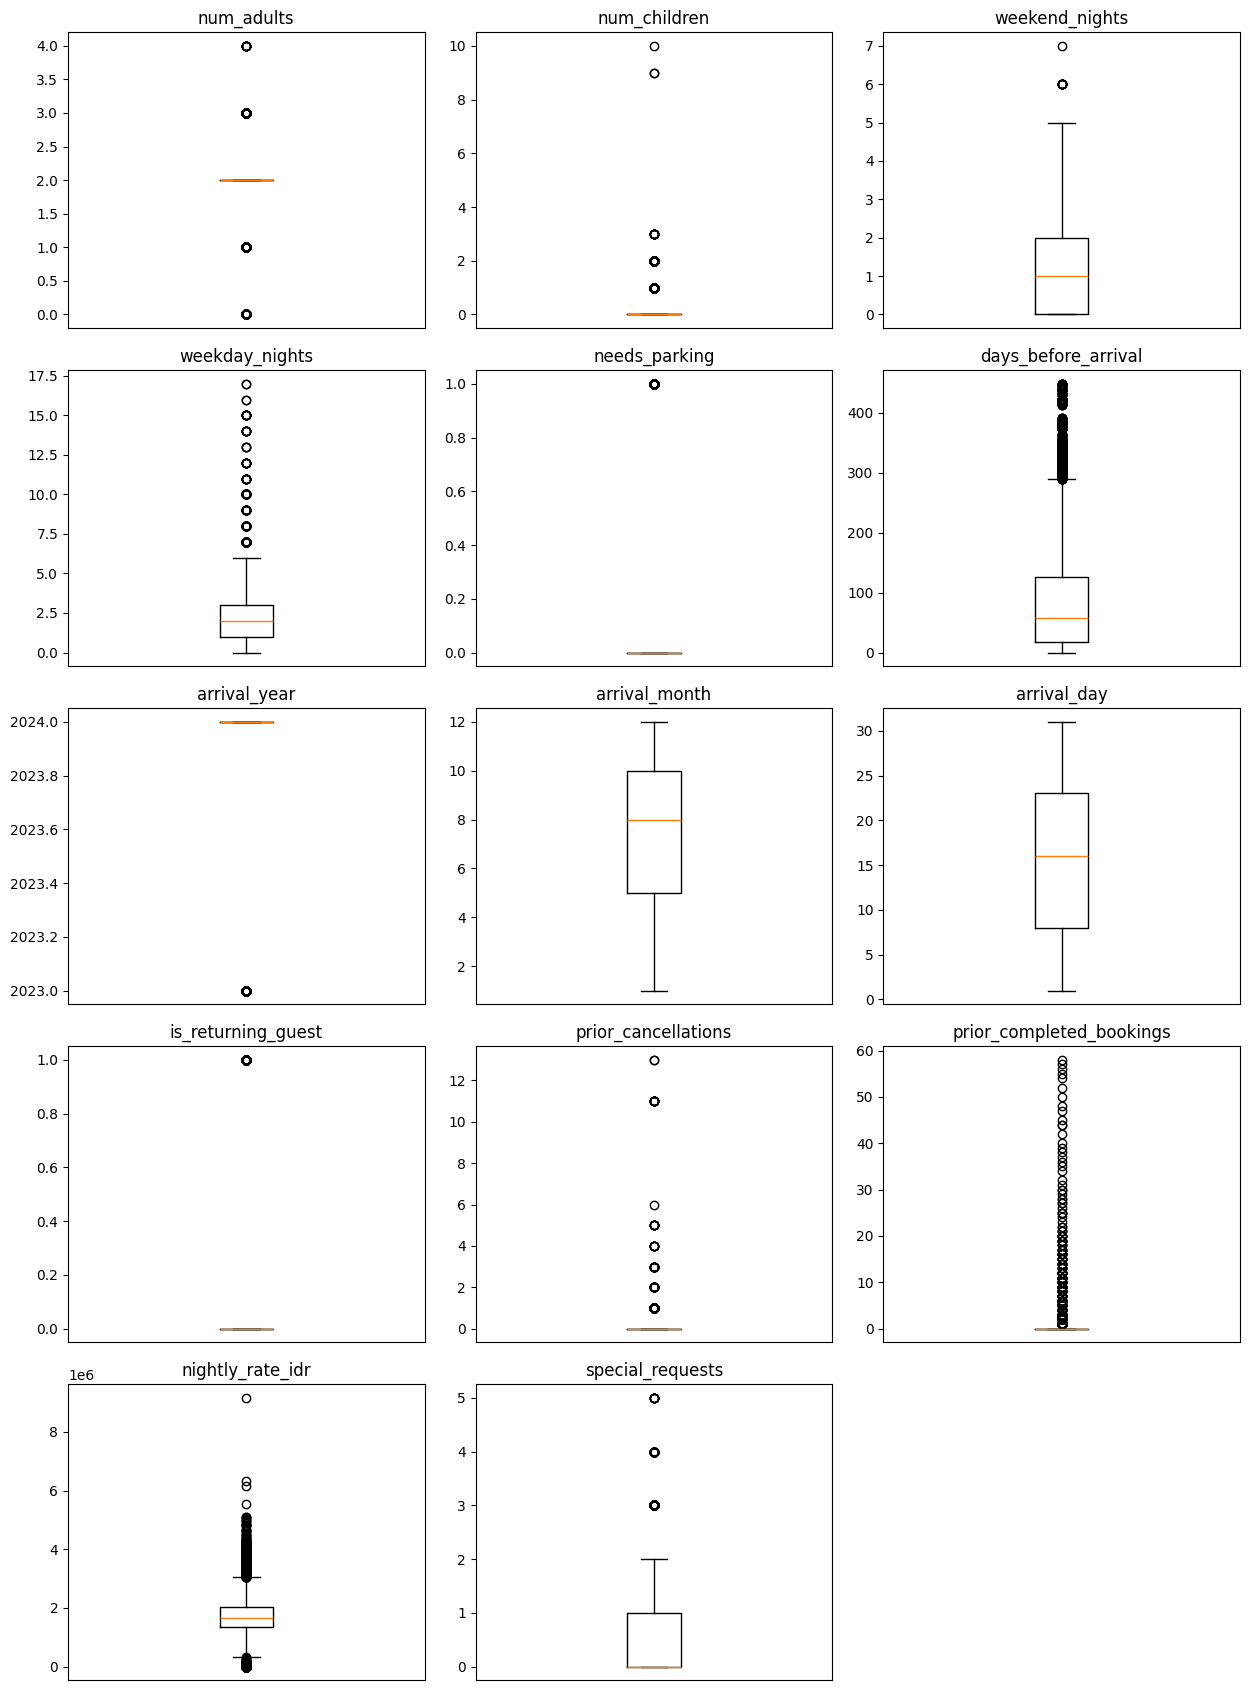

In [22]:
boxplot(num_col_df)

In [23]:
def target_rate(df, columns):
    for axis, column in zip(make_axes(len(as_list(columns)), ncols=2), as_list(columns)):
        df.groupby(column)[Settings.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {Settings.TARGET}')

    plt.tight_layout()
    plt.show()

def correlation(df):
    numbers = df.select_dtypes('number').drop(columns=[Settings.TARGET])
    values = numbers.corrwith(df[Settings.TARGET])

    return values.reindex(values.abs().sort_values(ascending=False).index)

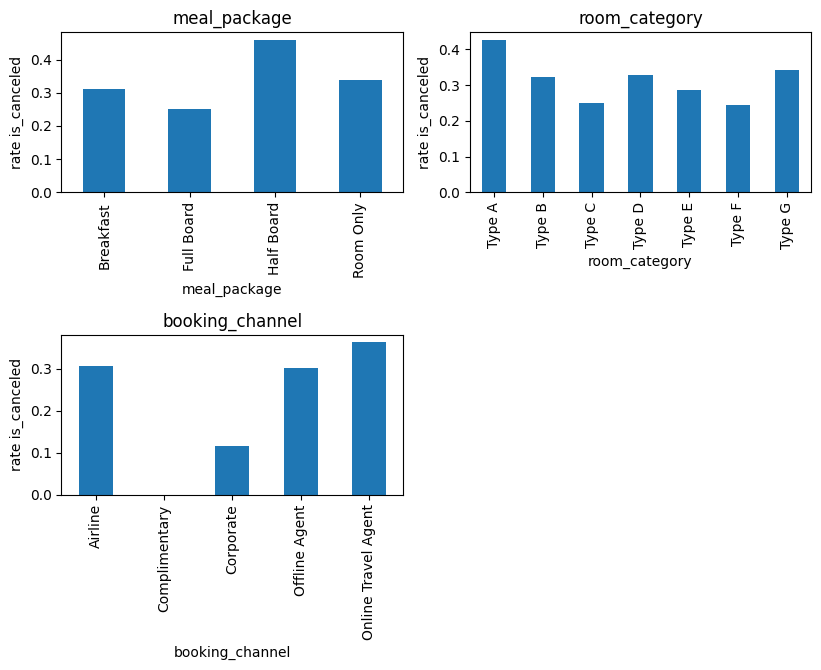

In [24]:
target_rate(train_df, cat_cols)

In [25]:
correlation(train_df)

,0
days_before_arrival,0.440316
special_requests,-0.257996
arrival_year,0.179826
nightly_rate_idr,0.134092
is_returning_guest,-0.107207
weekday_nights,0.097226
num_adults,0.088446
needs_parking,-0.085504
weekend_nights,0.060797
prior_completed_bookings,-0.058894


## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [26]:
def missing(train, test):
    features = test.columns.drop(Settings.ID_COLUMN)
    combined = pd.concat([train[features], test[features]])
    table = pd.DataFrame(
        {
            'train': train[features].isna().mean() * 100,
            'test': test[features].isna().mean() * 100,
            'combined': combined.isna().mean() * 100,
        }
    ).round(2)

    return table[table['combined'] > 0]

In [27]:
missing(train_df, test_df)

,train,test,combined
num_adults,2.96,2.63,2.89
num_children,11.09,10.91,11.05
meal_package,6.43,6.46,6.44
needs_parking,3.95,3.61,3.88
room_category,3.66,3.54,3.64
days_before_arrival,4.10,4.24,4.13
nightly_rate_idr,7.45,7.89,7.53
special_requests,9.13,8.66,9.04


In [28]:
def duplicates(train, test):
    features = test.columns.drop(Settings.ID_COLUMN)
    combined = pd.concat([train[features], test[features]])

    return pd.Series(
        {
            'train': train[features].duplicated().sum(),
            'test': test[features].duplicated().sum(),
            'combined': combined.duplicated().sum(),
        }
    )

In [29]:
duplicates(train_df, test_df)

,0
train,66
test,3
combined,109


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [30]:
X = train_df[feature_cols]
y = train_df[Settings.TARGET]

X_test = test_df[feature_cols]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=Settings.TEST_SIZE, stratify=y, random_state=Settings.SEED
)

pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

,0
X_train,21898
X_val,5475
X_test,6844


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [31]:
def impute(columns, strategy='median', zero_is_missing=False):
    columns = as_list(columns)
    frames = [X_train, X_val, X_test]

    if zero_is_missing:
        for frame in frames:
            frame[columns] = frame[columns].replace(0, np.nan)

    imputer = SimpleImputer(strategy=strategy).fit(X_train[columns])

    for frame in frames:
        frame[columns] = imputer.transform(frame[columns])

### Duplicates

This part covers repeated records.

In [32]:
# Write your code here

### Outliers

This part covers values far from the rest of the data.

In [33]:
def cap_outliers(columns, factor=1.5):
    columns = as_list(columns)
    q1, q3 = X_train[columns].quantile(0.25), X_train[columns].quantile(0.75)
    lower, upper = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)

    for frame in [X_train, X_val, X_test]:
        frame[columns] = frame[columns].clip(lower, upper, axis=1)

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [34]:
print("num_adults == 0 count:", (X_train['num_adults'] == 0).sum())
print("days_before_arrival > 365 count:", (X_train['days_before_arrival'] > 365).sum())
weekends = np.ceil(X_train['weekend_nights'] / 2)
weekdays = np.ceil(X_train['weekday_nights'] / 5)
inconsistent_check = (weekdays > weekends + 1) | (weekends > weekdays + 1)
print("Inconsistent nights count:", inconsistent_check.sum())

num_adults == 0 count: 84
days_before_arrival > 365 count: 150
Inconsistent nights count: 0


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [35]:
# Write your code here

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [36]:
def scale(columns, kind='standard'):
    columns = as_list(columns)
    scalers = {'standard': StandardScaler, 'minmax': MinMaxScaler, 'robust': RobustScaler}
    scaler = scalers[kind]().fit(X_train[columns])

    for frame in [X_train, X_val, X_test]:
        frame[columns] = scaler.transform(frame[columns])

### Encoding

This part covers the numeric representation of categorical attributes.

In [37]:
def encode(columns, kind='onehot', order=None):
    columns = as_list(columns)

    if kind == 'onehot':
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    else:
        categories = [order] * len(columns) if order else 'auto'
        encoder = OrdinalEncoder(categories=categories)

    encoder.fit(X_train[columns])
    names = list(encoder.get_feature_names_out(columns))

    for frame in [X_train, X_val, X_test]:
        encoded = encoder.transform(frame[columns])
        frame.drop(columns=columns, inplace=True)
        frame[names] = encoded

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [38]:
# Write your code here

## Class Balance

This part covers the proportion of each class in the training data.

In [39]:
def resample(X, y, method=None):
    if method is None:
        return X, y

    samplers = {'smote': SMOTE, 'undersample': RandomUnderSampler}

    return samplers[method](random_state=Settings.SEED).fit_resample(X, y)

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [40]:
# Write your code here

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [41]:
X_train.drop_duplicates()
y_train.drop_duplicates()

for df in [X_train, X_val, X_test]:
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan

    df.loc[df['days_before_arrival'] > 365, 'days_before_arrival'] = np.nan

    weekends = np.ceil(X_train['weekend_nights'] / 2)
    weekdays = np.ceil(X_train['weekday_nights'] / 5)
    inconsistent_mask = (weekdays > weekends + 1) | (weekends > weekdays + 1)
    X_train.loc[inconsistent_mask, ['weekend_nights', 'weekday_nights']] = np.nan

impute(num_cols, strategy='median')
impute(cat_cols, strategy='most_frequent')

# cap_outliers(num_cols)

encode(['room_category', 'booking_channel'])
encode('meal_package', 'ordinal', ['Room Only', 'Breakfast', 'Half Board', 'Full Board'])

scale(num_cols)



/tmp/ipykernel_3782/2733697685.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frame[columns] = imputer.transform(frame[columns])
/tmp/ipykernel_3782/2733697685.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frame[columns] = imputer.transform(frame[columns])
/tmp/ipykernel_3782/3969381321.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retu

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [42]:
class NotFittedError(ValueError, AttributeError):
    """Raised when the estimator is used before calling fit."""


def _to_2d_float_array(X):
    """DataFrame / Series / list / ndarray -> ((n, d) float64 array, feature names | None)."""
    names = None
    if hasattr(X, "to_numpy"):                      # pandas DataFrame / Series
        cols = getattr(X, "columns", None)
        arr = X.to_numpy()
        if cols is not None:
            names = np.asarray([str(c) for c in cols], dtype=object)
    else:
        arr = np.asarray(X)

    if arr.ndim != 2:
        raise ValueError(
            f"Expected 2D array, got {arr.ndim}D array instead. Reshape your data "
            "either with .reshape(-1, 1) if it has a single feature or with "
            ".reshape(1, -1) if it contains a single sample (for pandas: "
            "s.to_frame() or df.iloc[[i]])."
        )
    try:
        arr = np.asarray(arr, dtype=np.float64)
    except (TypeError, ValueError) as e:
        raise ValueError(f"X could not be converted to a numeric float64 array: {e}") from e
    if arr.shape[0] == 0:
        raise ValueError("Found array with 0 sample(s) while a minimum of 1 is required.")
    return arr, names


def _dist_block(A, B, metric, p):
    """Distances between rows of A (chunk) and rows of B. A:(s,d), B:(m,d) -> (s,m)."""
    if callable(metric):
        return np.asarray(metric(A, B), dtype=np.float64)

    if metric == "euclidean" or (metric == "minkowski" and p == 2):
        # ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b   (BLAS-friendly, no (s,m,d) temp)
        d2 = (np.einsum("ij,ij->i", A, A)[:, None]
              + np.einsum("ij,ij->i", B, B)[None, :]
              - 2.0 * (A @ B.T))
        np.maximum(d2, 0.0, out=d2)                 # clip tiny negatives from rounding
        return np.sqrt(d2, out=d2)

    diff = np.abs(A[:, None, :] - B[None, :, :])    # (s, m, d) broadcast
    if metric == "manhattan":
        return diff.sum(axis=2)
    if metric == "chebyshev":
        return diff.max(axis=2)
    if metric == "minkowski":
        if np.isinf(p):
            return diff.max(axis=2)                 # p = inf  ->  Chebyshev
        if p == 1:
            return diff.sum(axis=2)
        return (diff ** p).sum(axis=2) ** (1.0 / p)
    if metric == "cosine":
        num = A @ B.T
        na = np.sqrt(np.einsum("ij,ij->i", A, A))[:, None]
        nb = np.sqrt(np.einsum("ij,ij->i", B, B))[None, :]
        with np.errstate(divide="ignore", invalid="ignore"):
            d = 1.0 - num / (na * nb)
        return np.where(np.isnan(d), 1.0, d)        # zero-norm vectors -> treated as orthogonal
    raise ValueError(f"Unsupported metric {metric!r}; use one of {Settings.SUPPORTED_KNN_METRICS} or a callable.")


def _pairwise_distances(A, B, metric, p):
    """Full (n_A, n_B) distance matrix, computed in row-chunks of A."""
    n, d = A.shape
    m = B.shape[0]
    needs_diff = (not callable(metric)) and metric not in ("euclidean", "cosine") \
        and not (metric == "minkowski" and p == 2)
    per_row = (m * d) if needs_diff else max(m, 1)  # size of the temporary per row of A
    step = max(1, Settings.CHUNK_ELEMS // per_row)
    D = np.empty((n, m), dtype=np.float64)
    for s in range(0, n, step):
        D[s:s + step] = _dist_block(A[s:s + step], B, metric, p)
    return D


def _k_smallest(D, k):
    """Row-wise k smallest entries; ties broken by the smaller training index."""
    part = np.argpartition(D, k - 1, axis=1)[:, :k]
    dpart = np.take_along_axis(D, part, axis=1)
    order = np.lexsort((part, dpart), axis=1)       # primary: distance, secondary: index
    return (np.take_along_axis(dpart, order, axis=1),
            np.take_along_axis(part, order, axis=1))


def _get_neighbour_weights(dist, weights):
    """sklearn weight semantics. Returns None for 'uniform', else a (n_query, k) array."""
    if callable(weights):
        w = np.asarray(weights(dist), dtype=np.float64)
        if w.shape != dist.shape:
            raise ValueError("Custom weights callable must return an array with the "
                             "same shape as the distances.")
        return w
    if weights == "uniform":
        return None
    with np.errstate(divide="ignore"):
        w = 1.0 / dist
    inf_mask = np.isinf(w)
    if inf_mask.any():
        rows = inf_mask.any(axis=1)
        w[rows] = inf_mask[rows]
    return w


def _weighted_counts(neigh_labels, weights, n_classes):
    """(n_query, k) encoded labels + weights -> (n_query, n_classes) weighted vote counts."""
    nq, k = neigh_labels.shape
    w = np.full((nq, k), 1.0 / k) if weights is None else weights
    rows = np.repeat(np.arange(nq), k)
    flat = rows * n_classes + neigh_labels.ravel()
    counts = np.bincount(flat, weights=w.ravel(), minlength=nq * n_classes)
    return counts.reshape(nq, n_classes)


class _BaseKNeighborsFS:
    def __init__(self, n_neighbors=5, *, weights="uniform", algorithm="auto",
                 leaf_size=30, p=2, metric="minkowski", metric_params=None,
                 n_jobs=None):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.algorithm = algorithm
        self.leaf_size = leaf_size
        self.p = p
        self.metric = metric
        self.metric_params = metric_params
        self.n_jobs = n_jobs

    def get_params(self, deep=True):
        return {k: getattr(self, k) for k in
                ("n_neighbors", "weights", "algorithm", "leaf_size", "p",
                 "metric", "metric_params", "n_jobs")}

    def set_params(self, **params):
        valid = self.get_params()
        for key, value in params.items():
            if key not in valid:
                raise ValueError(f"Invalid parameter {key!r} for {type(self).__name__}. "
                                 "Valid parameters are: " + ", ".join(sorted(valid)) + ".")
            setattr(self, key, value)
        return self

    def __repr__(self):
        sig = inspect.signature(self.__init__)
        changed = [f"{k}={getattr(self, k)!r}"
                   for k, prm in sig.parameters.items()
                   if k != "self" and getattr(self, k) != prm.default]
        return f"{type(self).__name__}({', '.join(changed)})"

    def _resolve_metric(self):
        metric = self.metric
        if callable(metric):
            return metric, None
        if metric not in Settings.SUPPORTED_KNN_METRICS:
            raise ValueError(f"Unsupported metric {metric!r}."
                             f"implementation supports {Settings.SUPPORTED_KNN_METRICS} or a callable.")
        extra = dict(self.metric_params or {})
        if metric == "minkowski":
            p = extra.pop("p", self.p)
            if extra:
                raise ValueError(f"metric_params {extra!r} are not supported here.")
            try:
                p = float(p)
            except (TypeError, ValueError) as e:
                raise ValueError(f"p must be a float >= 1 or np.inf, got {p!r}.") from e
            if p != np.inf and not p >= 1:
                raise ValueError(f"p must be a float >= 1 or np.inf, got {p}.")
            return "minkowski", p
        if extra:
            raise ValueError(f"metric_params {extra!r} are not supported for metric {metric!r}.")
        return metric, None

    def _fit_common(self, X):
        if self.weights not in ("uniform", "distance") and not callable(self.weights):
            raise ValueError("weights must be 'uniform', 'distance' or a callable.")
        if self.algorithm not in ("auto", "brute", "kd_tree", "ball_tree"):
            raise ValueError("algorithm must be 'auto', 'brute', 'kd_tree' or 'ball_tree'.")
        X_arr, names = _to_2d_float_array(X)
        self._fit_X = X_arr
        self.n_samples_fit_ = X_arr.shape[0]
        self.n_features_in_ = X_arr.shape[1]
        self.feature_names_in_ = names
        self.effective_metric_, self.effective_p_ = self._resolve_metric()
        return X_arr

    def _check_fitted(self):
        if not hasattr(self, "_fit_X"):
            raise NotFittedError(
                f"This {type(self).__name__} instance is not fitted yet. Call 'fit' "
                "with appropriate arguments before using this estimator.")

    def _check_query(self, X):
        arr, names = _to_2d_float_array(X)
        if arr.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {arr.shape[1]} features, but {type(self).__name__} "
                             f"is expecting {self.n_features_in_} features as input.")
        if names is not None and self.feature_names_in_ is not None \
                and list(names) != list(self.feature_names_in_):
            raise ValueError(
                "The feature names should match those that were passed during fit.\n"
                f"Fit-time feature names:    {list(self.feature_names_in_)}\n"
                f"Predict-time feature names: {list(names)}")
        return arr

    def kneighbors(self, X=None, n_neighbors=None, return_distance=True):
        """Indices (and distances) of the k nearest training points for each query.

        X=None queries the training set itself; the point itself is then excluded
        (sklearn semantics). Returns (distances, indices) or just indices.
        """
        self._check_fitted()
        if n_neighbors is None:
            n_neighbors = self.n_neighbors
        try:
            n_neighbors = operator.index(n_neighbors)
        except TypeError as e:
            raise ValueError(f"n_neighbors must be an integer, got {n_neighbors!r}.") from e
        if n_neighbors < 1:
            raise ValueError(f"Expected n_neighbors > 0, but got {n_neighbors}.")

        query_is_train = X is None
        Xq = self._fit_X if query_is_train else self._check_query(X)
        k = n_neighbors + 1 if query_is_train else n_neighbors  # +1 to drop self later
        if k > self.n_samples_fit_:
            limit = self.n_samples_fit_ - 1 if query_is_train else self.n_samples_fit_
            raise ValueError(f"Expected n_neighbors <= {limit}, but got n_neighbors = {n_neighbors}.")

        D = _pairwise_distances(Xq, self._fit_X, self.effective_metric_, self.effective_p_)
        neigh_dist, neigh_ind = _k_smallest(D, k)
        if query_is_train:
            neigh_dist, neigh_ind = neigh_dist[:, 1:], neigh_ind[:, 1:]
        return (neigh_dist, neigh_ind) if return_distance else neigh_ind


class KNeighborsClassifierFS(_BaseKNeighborsFS):
    def fit(self, X, y):
        self._fit_common(X)
        y = np.asarray(y)
        if y.ndim == 2 and y.shape[1] == 1:
            y = y.ravel()
        if y.ndim not in (1, 2):
            raise ValueError(f"y must be 1D or 2D (multi-output), got {y.ndim}D.")
        if y.ndim == 2 and y.shape[1] == 0:
            raise ValueError("y must have at least one column.")
        if y.shape[0] != self.n_samples_fit_:
            raise ValueError("Found input variables with inconsistent numbers of samples: "
                             f"[{self.n_samples_fit_}, {y.shape[0]}].")
        if y.ndim == 1:
            self.outputs_2d_ = False
            self.classes_ = np.unique(y)
            self.n_classes_ = len(self.classes_)
            self._y = np.searchsorted(self.classes_, y).astype(np.intp)
        else:                                               # multi-output
            self.outputs_2d_ = True
            self.classes_ = [np.unique(y[:, i]) for i in range(y.shape[1])]
            self.n_classes_ = [len(c) for c in self.classes_]
            self._y = np.column_stack(
                [np.searchsorted(c, y[:, i]) for i, c in enumerate(self.classes_)]
            ).astype(np.intp)
        return self

    def fit_predict(self, X, y):
        return self.fit(X, y).predict(X)

    def predict(self, X):
        """Class labels for X. Multi-output y -> (n, n_outputs) array."""
        self._check_fitted()
        neigh_dist, neigh_ind = self.kneighbors(X)
        weights = _get_neighbour_weights(neigh_dist, self.weights)
        if self.outputs_2d_:
            cols = [self.classes_[o][_weighted_counts(
                        self._y[neigh_ind, o], weights, self.n_classes_[o]).argmax(axis=1)]
                    for o in range(len(self.classes_))]
            return np.stack(cols, axis=1)
        counts = _weighted_counts(self._y[neigh_ind], weights, self.n_classes_)
        return self.classes_[counts.argmax(axis=1)]

    def predict_proba(self, X):
        """Class probabilities (columns ordered like classes_). Multi-output -> list of arrays."""
        self._check_fitted()
        neigh_dist, neigh_ind = self.kneighbors(X)
        weights = _get_neighbour_weights(neigh_dist, self.weights)

        def normalise(counts):
            totals = counts.sum(axis=1, keepdims=True)
            return np.divide(counts, totals, out=np.zeros_like(counts), where=totals > 0)

        if self.outputs_2d_:
            return [normalise(_weighted_counts(self._y[neigh_ind, o], weights,
                                               self.n_classes_[o]))
                    for o in range(len(self.classes_))]
        return normalise(_weighted_counts(self._y[neigh_ind], weights, self.n_classes_))

    def predict_log_proba(self, X):
        proba = self.predict_proba(X)
        with np.errstate(divide="ignore"):
            return [np.log(p) for p in proba] if isinstance(proba, list) else np.log(proba)

    def score(self, X, y, sample_weight=None):
        """Mean accuracy (weighted by sample_weight if given)."""
        y = np.asarray(y)
        if y.ndim == 2 and y.shape[1] == 1:
            y = y.ravel()
        correct = self.predict(X) == y
        if sample_weight is not None:
            return float(np.average(correct, weights=sample_weight))
        return float(np.average(correct))

knn_fs = KNeighborsClassifierFS(n_neighbors=5, weights='distance')
knn_fs

KNeighborsClassifierFS(weights='distance')

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [62]:
def _safe_entropy_rows(P):
    """Row-wise Shannon entropy (in bits) of a probability matrix (..., K)."""
    P = np.clip(P, 0.0, 1.0)
    logs = np.where(P > 0.0, np.log2(np.maximum(P, Settings.EPS)), 0.0)
    return -np.sum(P * logs, axis=-1)


def _object_missing_mask(vals):
    """Element-wise missing mask for an object array (None/NaN/NaT/pd.NA)."""
    if pd is not None:
        return np.asarray(pd.isna(vals), dtype=bool)
    out = np.zeros(len(vals), dtype=bool)
    for i, v in enumerate(vals):
        out[i] = v is None or (isinstance(v, float) and math.isnan(v))
    return out


def _object_column_to_float(vals):
    """Object column -> float64 (missing -> NaN); raises on non-numeric junk."""
    miss = _object_missing_mask(vals)
    out = np.full(len(vals), np.nan, dtype=np.float64)
    keep = ~miss
    if keep.any():
        out[keep] = np.asarray(vals[keep], dtype=np.float64)
    return out


def _numeric_column(col):
    """Convert one column to float64 (NaN marks missing values)."""
    if hasattr(col, "to_numpy"):                       # pandas Series
        try:
            arr = col.to_numpy(dtype=np.float64, na_value=np.nan)
            return np.asarray(arr, dtype=np.float64).ravel()
        except TypeError:                              # very old pandas
            arr = col.to_numpy()
    else:
        arr = np.asarray(col)
    if arr.dtype.kind == "O":
        arr = _object_column_to_float(np.asarray(arr, dtype=object).ravel())
    else:
        arr = np.asarray(arr, dtype=np.float64)
    return np.asarray(arr, dtype=np.float64).ravel()


def _to_object_1d(col):
    """Convert one column to a 1-D object array (values kept as-is)."""
    if hasattr(col, "to_numpy"):
        arr = col.to_numpy(dtype=object)
    else:
        arr = np.asarray(col, dtype=object)
    return np.asarray(arr, dtype=object).ravel()


def _factorize_object(vals):
    """Encode an object array as int32 codes (-1 == missing). Returns (codes, uniques)."""
    miss = _object_missing_mask(vals)
    codes = np.full(len(vals), -1, dtype=np.int32)
    lookup, uniques = {}, []
    for i, v in enumerate(vals):
        if miss[i]:
            continue
        code = lookup.get(v)
        if code is None:
            code = len(uniques)
            lookup[v] = code
            uniques.append(v)
        codes[i] = code
    return codes, uniques


def _has_missing_labels(y):
    k = y.dtype.kind
    if k in ("f", "c"):
        return bool(np.isnan(y).any())
    if k == "O":
        return bool(_object_missing_mask(y).any())
    return False


def _coerce_columns(X):
    """Split X into per-column 1-D arrays + dtype kinds + names (or None)."""
    if pd is not None and isinstance(X, pd.DataFrame):
        names = [str(c) for c in X.columns]
        cols = [X.iloc[:, j] for j in range(X.shape[1])]
        kinds = []
        for col in cols:
            if pd.api.types.is_bool_dtype(col):
                kinds.append("categorical")
            elif pd.api.types.is_numeric_dtype(col):
                kinds.append("numeric")
            else:
                kinds.append("categorical")
        return cols, kinds, names
    arr = np.asarray(X)
    if arr.ndim != 2:
        raise ValueError(
            "X must be a 2-D array or a pandas DataFrame; got an object with "
            f"ndim={arr.ndim}. (A single pandas Series must be wrapped, e.g. df[[col]].)"
        )
    cols = [arr[:, j] for j in range(arr.shape[1])]
    kinds = ["numeric" if c.dtype.kind in ("f", "i", "u") else "categorical" for c in cols]
    return cols, kinds, None


def _resolve_count(value, total_w, name, int_min):
    if isinstance(value, bool):
        raise ValueError(f"{name} must be an int >= {int_min} or a float in (0, 1].")
    if isinstance(value, Integral):
        if value < int_min:
            raise ValueError(f"{name} must be >= {int_min} when given as an integer.")
        return float(value)
    if isinstance(value, Real):
        if not (0.0 < value <= 1.0):
            raise ValueError(f"{name} must be a float in (0, 1] when given as a float.")
        return float(max(int_min, math.ceil(value * total_w)))
    raise ValueError(f"{name} must be an int >= {int_min} or a float in (0, 1].")


class _Node:
    __slots__ = ("depth", "n_weighted", "class_counts", "is_leaf", "feature",
                 "ftype", "threshold", "cat_codes", "cat_index", "children",
                 "branch_probs", "gain", "leaf_id")

    def __init__(self, depth, n_weighted, class_counts):
        self.depth = depth
        self.n_weighted = float(n_weighted)       # total (possibly fractional) weight
        self.class_counts = class_counts          # weighted per-class counts, shape (K,)
        self.is_leaf = True
        self.feature = -1
        self.ftype = None                         # 'num' | 'cat'
        self.threshold = None                     # numeric split threshold
        self.cat_codes = None                     # categorical codes, one per child
        self.cat_index = None                     # {code: child position}
        self.children = None
        self.branch_probs = None                  # P(child i) for missing/unseen values
        self.gain = 0.0                           # impurity gain of the split (for importances)
        self.leaf_id = -1

    def __repr__(self):
        if self.is_leaf:
            return f"<leaf depth={self.depth} n={self.n_weighted:.4g}>"
        if self.ftype == "num":
            test = f"x[{self.feature}] <= {self.threshold:.4g}"
        else:
            test = f"x[{self.feature}] in {list(self.cat_codes)}"
        return f"<node {test} n={self.n_weighted:.4g} children={len(self.children)}>"


class C45DecisionTreeClassifier:
    def __init__(self,
                 criterion="entropy",
                 splitter="best",
                 max_depth=None,
                 min_samples_split=2,
                 min_samples_leaf=1,
                 min_weight_fraction_leaf=0.0,
                 max_features=None,
                 class_weight=None,
                 min_impurity_decrease=0.0,
                 pruning=True,
                 cf=0.25,
                 random_state=None):
        self.criterion = criterion
        self.splitter = splitter
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_weight_fraction_leaf = min_weight_fraction_leaf
        self.max_features = max_features
        self.class_weight = class_weight
        self.min_impurity_decrease = min_impurity_decrease
        self.pruning = pruning
        self.cf = cf
        self.random_state = random_state

    @classmethod
    def _get_param_names(cls):
        sig = inspect.signature(cls.__init__)
        return [n for n, p in sig.parameters.items()
                if n != "self" and p.kind not in (p.VAR_POSITIONAL, p.VAR_KEYWORD)]

    def get_params(self, deep=True):
        return {name: getattr(self, name) for name in self._get_param_names()}

    def set_params(self, **params):
        valid = set(self._get_param_names())
        for key, value in params.items():
            if key not in valid:
                raise ValueError(f"Invalid parameter {key!r} for {type(self).__name__}.")
            setattr(self, key, value)
        return self

    def __repr__(self):
        parts = []
        for name, param in inspect.signature(type(self).__init__).parameters.items():
            if name == "self":
                continue
            cur = getattr(self, name, None)
            if cur != param.default:
                parts.append(f"{name}={cur!r}")
        return f"{type(self).__name__}({', '.join(parts)})"

    def _validate_params(self):
        if self.criterion not in ("gini", "entropy", "log_loss"):
            raise ValueError(f"criterion must be 'gini', 'entropy' or 'log_loss', got {self.criterion!r}")
        if self.splitter != "best":
            raise ValueError("splitter must be 'best' (C4.5 always selects the best test at a node).")
        if self.max_depth is not None:
            if isinstance(self.max_depth, bool) or not isinstance(self.max_depth, Integral) \
                    or self.max_depth < 1:
                raise ValueError("max_depth must be None or a positive integer.")
        if not (0.0 < float(self.cf) < 0.5):
            raise ValueError("cf (confidence factor) must be in (0, 0.5).")
        if not (0.0 <= float(self.min_weight_fraction_leaf) <= 0.5):
            raise ValueError("min_weight_fraction_leaf must be in [0, 0.5].")
        if isinstance(self.min_impurity_decrease, Real) and self.min_impurity_decrease < 0:
            raise ValueError("min_impurity_decrease must be >= 0.")
        cw = self.class_weight
        if cw is not None and not (cw == "balanced" or isinstance(cw, dict)):
            raise ValueError("class_weight must be None, 'balanced' or a dict.")

    def _resolve_max_features(self, p):
        mf = self.max_features
        if mf is None:
            return p
        if isinstance(mf, str):
            if mf in ("sqrt", "auto"):
                return max(1, int(math.sqrt(p)))
            if mf == "log2":
                return max(1, int(math.log2(p)))
            raise ValueError("max_features string must be 'sqrt', 'log2' or 'auto'.")
        if isinstance(mf, bool):
            raise ValueError("max_features must not be a bool.")
        if isinstance(mf, Integral):
            if not (1 <= mf <= p):
                raise ValueError(f"max_features must be in [1, {p}] as an integer.")
            return int(mf)
        if isinstance(mf, Real) and 0.0 < mf <= 1.0:
            return max(1, int(mf * p))
        raise ValueError("max_features must be None, 'sqrt', 'log2', 'auto', an int or a float in (0, 1].")

    def fit(self, X, y, sample_weight=None):
        self._validate_params()
        rng = np.random.default_rng(self.random_state)

        cols, kinds, names = _coerce_columns(X)
        if not cols:
            raise ValueError("X must contain at least one feature.")
        n = cols[0].shape[0]
        if any(c.shape[0] != n for c in cols):
            raise ValueError("All columns of X must have the same length.")
        if n == 0:
            raise ValueError("Found array with 0 sample(s); a minimum of 1 is required.")

        # Encode features: global column indexing for both matrices
        p = len(cols)
        X_num = np.full((n, p), np.nan, dtype=np.float64)   # NaN  = missing numeric
        X_cat = np.full((n, p), -1, dtype=np.int32)         # -1   = missing categorical
        feature_types, categories = [], []
        for j, (col, kind) in enumerate(zip(cols, kinds)):
            if kind == "numeric":
                X_num[:, j] = _numeric_column(col)
                feature_types.append("numeric")
                categories.append(None)
            else:
                codes, uniq = _factorize_object(_to_object_1d(col))
                X_cat[:, j] = codes
                feature_types.append("categorical")
                categories.append(uniq)

        # Encode labels
        y_arr = np.asarray(y)
        if y_arr.ndim == 2 and y_arr.shape[1] == 1:
            y_arr = y_arr.ravel()
        if y_arr.ndim != 1:
            raise NotImplementedError("Only single-output classification is supported (y must be 1-D).")
        if y_arr.shape[0] != n:
            raise ValueError(f"X has {n} samples but y has {y_arr.shape[0]}.")
        if _has_missing_labels(y_arr):
            raise ValueError("y contains null/NaN values; labels must be complete.")
        classes_, y_enc = np.unique(y_arr, return_inverse=True)
        y_enc = np.asarray(y_enc, dtype=np.int64).ravel()
        K = int(classes_.shape[0])

        # Weights
        if sample_weight is None:
            w = np.ones(n, dtype=np.float64)
        else:
            w = np.asarray(sample_weight, dtype=np.float64).ravel()
            if w.shape[0] != n:
                raise ValueError("sample_weight length does not match X.")
            if not np.all(np.isfinite(w)):
                raise ValueError("sample_weight contains NaN/inf.")
            if np.any(w < 0):
                raise ValueError("sample_weight must be non-negative.")
        if self.class_weight is None:
            cls_w = np.ones(K, dtype=np.float64)
        elif isinstance(self.class_weight, str) and self.class_weight == "balanced":
            freq = np.bincount(y_enc, minlength=K).astype(np.float64)
            cls_w = n / (K * np.maximum(freq, 1.0))
        elif isinstance(self.class_weight, dict):
            cls_w = np.ones(K, dtype=np.float64)
            for k, cls in enumerate(classes_):
                if cls in self.class_weight:
                    cls_w[k] = float(self.class_weight[cls])
        else:
            raise ValueError("class_weight must be None, 'balanced' or a dict.")
        w = w * cls_w[y_enc]
        total_w = float(w.sum())
        if total_w <= 0.0:
            raise ValueError("Total sample weight is zero.")

        # Resolved hyper-parameters
        max_depth_eff = math.inf if self.max_depth is None else int(self.max_depth)
        mss_w = _resolve_count(self.min_samples_split, total_w, "min_samples_split", 2)
        msl_w = _resolve_count(self.min_samples_leaf, total_w, "min_samples_leaf", 1)
        mwfl = float(self.min_weight_fraction_leaf)
        m_feats = self._resolve_max_features(p)
        self._z = NormalDist().inv_cdf(1.0 - float(self.cf))   # one-sided normal quantile

        # Tree induction (C4.5)
        def impurity_rows(C):
            C = np.asarray(C, dtype=np.float64)
            tot = C.sum(axis=-1, keepdims=True)
            P = np.divide(C, tot, out=np.zeros_like(C), where=tot > 0)
            if self.criterion == "gini":
                return 1.0 - np.sum(P * P, axis=-1)
            return _safe_entropy_rows(P)                    # 'entropy' / 'log_loss'

        def sample_features(avail):
            if m_feats >= avail.size:
                return avail
            return rng.choice(avail, size=int(m_feats), replace=False)

        def eval_numeric(f, idx, wts):
            v = X_num[idx, f]
            known = ~np.isnan(v)
            if not known.any():
                return None
            W = float(wts.sum())
            Wk = float(wts[known].sum())
            if Wk <= 0.0:
                return None
            F = Wk / W
            vk, wk, yk = v[known], wts[known], y_enc[idx[known]]
            order = np.argsort(vk, kind="stable")
            vs, ws, ys = vk[order], wk[order], yk[order]
            b = np.flatnonzero(vs[1:] != vs[:-1])           # candidate boundaries
            if b.size == 0:
                return None
            tot = np.bincount(ys, weights=ws, minlength=K)
            OH = np.zeros((vs.size, K))
            OH[np.arange(vs.size), ys] = ws
            L = np.cumsum(OH, axis=0)[b]                    # weighted class counts, left
            R = tot - L                                     # and right
            WL, WR = L.sum(axis=1), R.sum(axis=1)
            # Structural validity: child weight (incl. distributed unknowns,
            # which is W_side / F) must respect min_samples_leaf etc.
            valid = (WL > 0.0) & (WR > 0.0) & (WL >= msl_w * F) & (WR >= msl_w * F)
            if mwfl > 0.0:
                valid &= (WL >= mwfl * F * total_w) & (WR >= mwfl * F * total_w)
            if not valid.any():
                return None
            imp_known = float(impurity_rows(tot[None, :])[0])
            info_after = (WL / Wk) * impurity_rows(L) + (WR / Wk) * impurity_rows(R)
            gains = np.maximum(F * (imp_known - info_after), 0.0)
            sinfo = _safe_entropy_rows(np.stack([WL, WR], axis=1) / Wk)
            ratios = np.where(sinfo > Settings.EPS, gains / np.maximum(sinfo, Settings.EPS), 0.0)
            # threshold between vs[b] and vs[b+1]; avoid midpoint with +inf
            thr = np.where(vs[b + 1] == np.inf, vs[b], (vs[b] + vs[b + 1]) / 2.0)
            return {"f": f, "kind": "num", "gains": gains, "sinfo": sinfo,
                    "ratios": ratios, "valid": valid, "thr": thr}

        def eval_categorical(f, idx, wts):
            c = X_cat[idx, f]
            known = c >= 0
            if not known.any():
                return None
            W = float(wts.sum())
            wk = wts[known]
            Wk = float(wk.sum())
            if Wk <= 0.0:
                return None
            F = Wk / W
            ck, yk = c[known], y_enc[idx[known]]
            n_cats = len(categories[f])
            sizes = np.bincount(ck, weights=wk, minlength=n_cats)
            present = np.flatnonzero(sizes > 0)
            if present.size < 2:
                return None
            tot = np.bincount(yk, weights=wk, minlength=K)
            comp = ck.astype(np.int64) * K + yk
            cc_all = np.bincount(comp, weights=wk, minlength=n_cats * K).reshape(n_cats, K)
            imp_known = float(impurity_rows(tot[None, :])[0])
            probs = sizes[present] / Wk                     # branch probabilities (known cases)
            info_after = float(np.dot(probs, impurity_rows(cc_all[present])))
            gain = max(F * (imp_known - info_after), 0.0)
            sinfo = float(_safe_entropy_rows(probs[None, :])[0])
            s_children = sizes[present] / F                 # child weight incl. unknowns
            ok = bool(np.all(s_children > 0.0) and np.all(s_children >= msl_w))
            if ok and mwfl > 0.0:
                ok = bool(np.all(s_children >= mwfl * total_w))
            if not ok or sinfo <= Settings.EPS:
                return None
            return {"f": f, "kind": "cat", "gain": gain, "sinfo": sinfo,
                    "ratio": gain / sinfo, "present": present}

        def build_node(idx, wts, depth, avail):
            counts = np.bincount(y_enc[idx], weights=wts, minlength=K)
            node = _Node(depth, float(wts.sum()), counts)
            W = node.n_weighted

            # stopping rules
            if (W <= 0.0 or idx.size < 2 or depth >= max_depth_eff
                    or W < mss_w or np.count_nonzero(counts) <= 1):
                return node

            # collect candidate tests
            records, gain_sum, gain_cnt = [], 0.0, 0
            for f in sample_features(avail):
                f = int(f)
                rec = (eval_numeric(f, idx, wts) if feature_types[f] == "numeric"
                       else eval_categorical(f, idx, wts))
                if rec is None:
                    continue
                if rec["kind"] == "num":
                    g = rec["gains"][rec["valid"] & (rec["gains"] > Settings.EPS)]
                    if g.size:
                        gain_sum += float(g.sum())
                        gain_cnt += int(g.size)
                elif rec["gain"] > Settings.EPS:
                    gain_sum += rec["gain"]
                    gain_cnt += 1
                records.append(rec)
            if gain_cnt == 0:
                return node                                  # no informative test -> leaf
            avg_gain = gain_sum / gain_cnt

            # C4.5 selection: above-average gain, then max gain ratio
            best_ratio, best_gain, best = -np.inf, 0.0, None
            for rec in records:
                if rec["kind"] == "num":
                    eligible = (rec["valid"] & (rec["gains"] > Settings.EPS)
                                & (rec["gains"] >= avg_gain - 1e-15)
                                & (rec["sinfo"] > Settings.EPS))
                    if not eligible.any():
                        continue
                    j = int(np.argmax(np.where(eligible, rec["ratios"], -np.inf)))
                    ratio, gain = float(rec["ratios"][j]), float(rec["gains"][j])
                    payload = ("num", rec["f"], float(rec["thr"][j]))
                else:
                    if not (rec["gain"] > Settings.EPS and rec["gain"] >= avg_gain - 1e-15):
                        continue
                    ratio, gain = rec["ratio"], rec["gain"]
                    payload = ("cat", rec["f"], rec["present"])
                if ratio > best_ratio + 1e-15:
                    best_ratio, best_gain, best = ratio, gain, payload
            if best is None or best_gain <= Settings.EPS:
                return node
            if (W / total_w) * best_gain < float(self.min_impurity_decrease):
                return node

            # apply the chosen test (fractional distribution of unknowns)
            kind, f, payload = best
            node.is_leaf, node.feature, node.ftype, node.gain = False, f, kind, best_gain
            v = X_num[idx, f] if kind == "num" else X_cat[idx, f]
            known = ~np.isnan(v) if kind == "num" else (v >= 0)
            unk_idx, w_unk = idx[~known], wts[~known]
            ik, wk2 = idx[known], wts[known]
            Wk = float(wk2.sum())

            if kind == "num":
                thr = payload
                node.threshold = thr
                lm = v[known] <= thr
                p_left = float(wk2[lm].sum()) / Wk
                p_right = 1.0 - p_left
                specs = [
                    (np.concatenate([ik[lm], unk_idx]),
                     np.concatenate([wk2[lm], w_unk * p_left]), p_left),
                    (np.concatenate([ik[~lm], unk_idx]),
                     np.concatenate([wk2[~lm], w_unk * p_right]), p_right),
                ]
                child_avail = avail
            else:
                node.cat_codes = np.asarray(payload, dtype=np.int32)
                node.cat_index = {int(c): i for i, c in enumerate(payload)}
                ck = v[known]
                sizes = np.bincount(ck, weights=wk2)[payload]
                probs = sizes / sizes.sum()
                specs = []
                for code, pr in zip(payload, probs):
                    m = ck == code
                    specs.append((np.concatenate([ik[m], unk_idx]),
                                  np.concatenate([wk2[m], w_unk * pr]), float(pr)))
                child_avail = avail[avail != f]              # do not re-test this attribute

            bp = np.array([s[2] for s in specs], dtype=np.float64)
            node.branch_probs = bp / bp.sum()
            node.children = [build_node(ci, cw, depth + 1, child_avail)
                             for (ci, cw, _pr) in specs]
            return node

        root = build_node(np.arange(n), w, 0, np.arange(p))

        # Post-pruning (C4.5 error-based pruning)
        if self.pruning:
            self._prune_node(root)

        # Finalise public attributes
        self._n_leaves = self._assign_leaf_ids(root)
        importance = np.zeros(p, dtype=np.float64)
        self._accumulate_importance(root, total_w, importance)
        denom = float(importance.sum())
        self._importances = importance / denom if denom > 0 else importance.copy()

        self.tree_ = root
        self.classes_ = classes_
        self.n_classes_ = K
        self.n_outputs_ = 1
        self.n_features_in_ = p
        self.feature_names_in_ = (np.asarray(names, dtype=object)
                                  if names is not None else None)
        self.feature_types_in_ = feature_types
        self.categories_ = categories
        self._cat_maps = [({v: i for i, v in enumerate(u)} if u else {})
                          for u in categories]
        return self

    def _upper_error_rate(self, N, J):
        if N <= 0:
            return 1.0
        cf = float(self.cf)
        if J <= 0.0:
            # exact binomial limit: P(X = 0 | N, U) = cf  =>  U = 1 - cf**(1/N)
            return min(1.0, 1.0 - cf ** (1.0 / N))
        # normal (Wilson) approximation; valid for fractional counts as well
        z = self._z
        var = J * (1.0 - J / N) + 0.25 * z * z
        U = (J + 0.5 * z * z + z * math.sqrt(max(var, 0.0))) / (N + z * z)
        return float(min(1.0, max(0.0, U)))

    def _leaf_error_estimate(self, node):
        N = node.n_weighted
        if N <= 0:
            return 0.0
        J = N - float(node.class_counts.max())
        return self._upper_error_rate(N, J) * N

    def _prune_node(self, node):
        if node.is_leaf:
            return self._leaf_error_estimate(node)
        child_ests = [self._prune_node(ch) for ch in node.children]
        subtree_est = float(sum(child_ests))
        leaf_est = self._leaf_error_estimate(node)
        # subtree raising: replace the subtree by the most frequently used branch
        bi = int(np.argmax(node.branch_probs))
        child = node.children[bi]
        raise_est = (child_ests[bi] * node.n_weighted / child.n_weighted
                     if child.n_weighted > 0 else np.inf)
        if leaf_est <= subtree_est and leaf_est <= raise_est:
            self._turn_into_leaf(node)
            return leaf_est
        if raise_est < subtree_est:
            factor = node.n_weighted / child.n_weighted
            self._rescale_subtree(child, factor)
            node.feature, node.ftype = child.feature, child.ftype
            node.threshold, node.cat_codes = child.threshold, child.cat_codes
            node.cat_index, node.children = child.cat_index, child.children
            node.branch_probs, node.is_leaf = child.branch_probs, child.is_leaf
            node.gain = child.gain
            node.n_weighted, node.class_counts = child.n_weighted, child.class_counts
            return raise_est
        return subtree_est

    def _turn_into_leaf(self, node):
        node.is_leaf = True
        node.feature, node.ftype = -1, None
        node.threshold = node.cat_codes = node.cat_index = None
        node.children = node.branch_probs = None

    def _rescale_subtree(self, node, factor):
        stack = [node]
        while stack:
            nd = stack.pop()
            nd.n_weighted *= factor
            nd.class_counts = nd.class_counts * factor
            if not nd.is_leaf:
                stack.extend(nd.children)

    def _assign_leaf_ids(self, root):
        count, stack = 0, [root]
        while stack:
            nd = stack.pop()
            if nd.is_leaf:
                nd.leaf_id = count
                count += 1
            else:
                stack.extend(reversed(nd.children))
        return count

    def _accumulate_importance(self, node, total_w, out):
        stack = [node]
        while stack:
            nd = stack.pop()
            if nd.is_leaf:
                continue
            out[nd.feature] += (nd.n_weighted / total_w) * nd.gain
            stack.extend(nd.children)


    def _check_fitted(self):
        if getattr(self, "tree_", None) is None:
            raise ValueError("This C45DecisionTreeClassifier instance is not fitted yet. "
                             "Call 'fit' with X and y before using this estimator.")

    def _transform_X(self, X):
        cols, kinds, names = _coerce_columns(X)
        if len(cols) != self.n_features_in_:
            raise ValueError(f"X has {len(cols)} features, but {type(self).__name__} "
                             f"is expecting {self.n_features_in_} features as input.")
        if names is not None and self.feature_names_in_ is not None:
            if [str(c) for c in names] != [str(v) for v in self.feature_names_in_]:
                raise ValueError("The feature names should match those that were "
                                 f"passed during fit.\nFit names: {list(self.feature_names_in_)}"
                                 f"\nX names   : {names}")
        n = cols[0].shape[0] if cols else 0
        X_num = np.full((n, self.n_features_in_), np.nan, dtype=np.float64)
        X_cat = np.full((n, self.n_features_in_), -1, dtype=np.int32)
        for j, col in enumerate(cols):
            if self.feature_types_in_[j] == "numeric":
                try:
                    X_num[:, j] = _numeric_column(col)
                except (TypeError, ValueError) as exc:
                    label = names[j] if names else f"x[{j}]"
                    raise ValueError(f"Column '{label}' was numeric during fit but "
                                     f"cannot be converted to float at predict time.") from exc
            else:
                vals = _to_object_1d(col)
                miss = _object_missing_mask(vals)
                cmap = self._cat_maps[j]
                codes = X_cat[:, j]
                for i in range(n):
                    if not miss[i]:
                        codes[i] = cmap.get(vals[i], -1)   # unseen category -> missing
                X_cat[:, j] = codes
        return X_num, X_cat, n

    def predict_proba(self, X):
        self._check_fitted()
        X_num, X_cat, n = self._transform_X(X)
        K = self.n_classes_
        proba = np.zeros((n, K))
        for i in range(n):
            acc = proba[i]
            stack = [(self.tree_, 1.0)]
            while stack:
                node, mass = stack.pop()
                if node.is_leaf:
                    if node.n_weighted > 0:
                        acc += mass * (node.class_counts / node.n_weighted)
                    else:
                        acc += mass / K
                    continue
                if node.ftype == "num":
                    val = X_num[i, node.feature]
                    if math.isnan(val):
                        for ch, pr in zip(node.children, node.branch_probs):
                            if pr > 0.0:
                                stack.append((ch, mass * pr))
                    else:
                        stack.append((node.children[0 if val <= node.threshold else 1], mass))
                else:
                    code = int(X_cat[i, node.feature])
                    pos = node.cat_index.get(code) if code >= 0 else None
                    if pos is None:                        # missing or unseen category
                        for ch, pr in zip(node.children, node.branch_probs):
                            if pr > 0.0:
                                stack.append((ch, mass * pr))
                    else:
                        stack.append((node.children[pos], mass))
        row = proba.sum(axis=1, keepdims=True)
        return np.divide(proba, row, out=proba, where=row > 0)

    def predict(self, X):
        proba = self.predict_proba(X)
        return self.classes_[np.argmax(proba, axis=1)]

    def predict_log_proba(self, X):
        proba = self.predict_proba(X)
        out = np.full(proba.shape, -np.inf)
        np.log(proba, out=out, where=proba > 0)
        return out

    def apply(self, X):
        self._check_fitted()
        X_num, X_cat, n = self._transform_X(X)
        out = np.empty(n, dtype=np.int64)
        for i in range(n):
            node = self.tree_
            while not node.is_leaf:
                if node.ftype == "num":
                    val = X_num[i, node.feature]
                    if math.isnan(val):
                        node = node.children[int(np.argmax(node.branch_probs))]
                    else:
                        node = node.children[0 if val <= node.threshold else 1]
                else:
                    code = int(X_cat[i, node.feature])
                    pos = node.cat_index.get(code) if code >= 0 else None
                    node = (node.children[int(np.argmax(node.branch_probs))]
                            if pos is None else node.children[pos])
            out[i] = node.leaf_id
        return out

    def score(self, X, y, sample_weight=None):
        y_arr = np.asarray(y)
        if y_arr.ndim == 2 and y_arr.shape[1] == 1:
            y_arr = y_arr.ravel()
        pred = self.predict(X)
        if sample_weight is None:
            return float(np.mean(pred == y_arr))
        w = np.asarray(sample_weight, dtype=np.float64).ravel()
        return float(np.average(pred == y_arr, weights=w))


    @property
    def feature_importances_(self):
        self._check_fitted()
        return self._importances.copy()

    def get_depth(self):
        """Depth of the fitted tree (a single leaf has depth 0)."""
        self._check_fitted()
        depth, stack = 0, [(self.tree_, 0)]
        while stack:
            nd, dep = stack.pop()
            depth = max(depth, dep)
            if not nd.is_leaf:
                stack.extend((ch, dep + 1) for ch in nd.children)
        return depth

    def get_n_leaves(self):
        self._check_fitted()
        return self._n_leaves

    def export_text(self, feature_names=None, max_depth=None, decimals=3):
        """Return a text rendering of the fitted tree.

        Numeric tests are shown as ``feature <= t`` / ``feature > t``;
        categorical tests as ``feature == value``. Missing values are routed
        probabilistically at prediction time (not shown).
        """
        self._check_fitted()
        if feature_names is None:
            feature_names = ([str(v) for v in self.feature_names_in_]
                             if self.feature_names_in_ is not None
                             else [f"x[{j}]" for j in range(self.n_features_in_)])
        lines = []

        def rec(node, indent):
            if node.is_leaf or (max_depth is not None and node.depth >= max_depth):
                N = node.n_weighted
                k = int(np.argmax(node.class_counts))
                probs = (node.class_counts / N if N > 0
                         else np.full(self.n_classes_, 1.0 / self.n_classes_))
                dist = ", ".join(f"{c!r}:{q:.3f}" for c, q in zip(self.classes_, probs))
                lines.append(f"{indent}|--- class: {self.classes_[k]!r}   "
                             f"(n={N:.4g}; probs=[{dist}])")
                return
            name = feature_names[node.feature]
            if node.ftype == "num":
                thr = f"{node.threshold:.{decimals}g}"
                lines.append(f"{indent}|--- {name} <= {thr}")
                rec(node.children[0], indent + "|   ")
                lines.append(f"{indent}|--- {name} >  {thr}")
                rec(node.children[1], indent + "|   ")
            else:
                cats = self.categories_[node.feature]
                for code, ch in zip(node.cat_codes, node.children):
                    lines.append(f"{indent}|--- {name} == {cats[int(code)]!r}")
                    rec(ch, indent + "|   ")

        rec(self.tree_, "")
        return "\n".join(lines)
dtl = C45DecisionTreeClassifier()
dtl

C45DecisionTreeClassifier()

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [64]:
def _softmax(S):
    S = S - S.max(axis=1, keepdims=True)
    E = np.exp(S)
    return E / E.sum(axis=1, keepdims=True)


def _largest_singular_value_sq(A, n_iter=50):
    v = np.full(A.shape[1], 1.0 / math.sqrt(A.shape[1]))
    s = 0.0
    for _ in range(n_iter):
        u = A @ v
        s = float(math.sqrt(float(u @ u)))
        if s <= 1e-300:
            return 0.0
        v = A.T @ u
        nv = math.sqrt(float(v @ v))
        if nv <= 1e-300:
            return 0.0
        v /= nv
    return s * s


def _make_prox_pen(mu1, mu2):
    """Proximal operator and value of  mu1*|.|_1 + 0.5*mu2*|.|_2^2  (element-wise).

    prox_t(v) = sign(v) * max(|v| - t*mu1, 0) / (1 + t*mu2)   (exact for elastic net)
    """
    def prox(V, t):
        U = V
        if mu1 > 0.0:
            U = np.sign(U) * np.maximum(np.abs(U) - t * mu1, 0.0)
        if mu2 > 0.0:
            U = U / (1.0 + t * mu2)
        return U

    def pen(V):
        if mu1 == 0.0 and mu2 == 0.0:
            return 0.0
        return float(mu1 * np.abs(V).sum() + 0.5 * mu2 * np.sum(V * V))

    return prox, pen


def _run_fista(smooth_value, smooth_value_grad, prox_fn, pen_fn,
               w, b, t0, max_iter, tol, verbose):
    """Returns (w, b, n_iter, converged).    """
    f_prev = smooth_value(w, b) + pen_fn(w)
    z_w = np.array(w, copy=True)          # momentum (extrapolation) point
    z_b = b + 0.0
    t_seq = 1.0                           # FISTA momentum schedule
    t = max(float(t0), 1e-10)             # proximal step size (line-searched)
    n_iter, converged = 0, False

    for it in range(1, int(max_iter) + 1):
        n_iter = it
        f_z, gw, gb = smooth_value_grad(z_w, z_b)

        # optimistic step growth + backtracking on the smooth majorization:
        #   g(w_new) <= g(z) + <grad, d> + ||d||^2 / (2t)
        t = min(2.0 * t, 1e8)
        for _ in range(60):
            w_new = prox_fn(z_w - t * gw, t)
            b_new = z_b - t * gb
            f_s_new = smooth_value(w_new, b_new)
            d_w, d_b = w_new - z_w, b_new - z_b
            quad = (f_z + float(np.sum(gw * d_w)) + float(np.sum(gb * d_b))
                    + 0.5 * float(np.sum(d_w * d_w) + np.sum(d_b * d_b)) / t)
            if f_s_new <= quad + 1e-12 * (1.0 + abs(f_z)):
                break
            t *= 0.5

        f_new = f_s_new + pen_fn(w_new)

        # proximal-gradient mapping surrogate at the evaluation point z
        gm = max(float(np.max(np.abs(z_w - w_new))),
                 float(np.max(np.abs(z_b - b_new)))) / t

        w_old, b_old = w, b
        if f_new > f_prev:                # adaptive restart (objective increased)
            z_w, z_b = np.array(w_new, copy=True), b_new + 0.0
            t_seq = 1.0
        else:                             # FISTA momentum step
            t_seq_new = 0.5 * (1.0 + math.sqrt(1.0 + 4.0 * t_seq * t_seq))
            beta = (t_seq - 1.0) / t_seq_new
            z_w = w_new + beta * (w_new - w_old)
            z_b = b_new + beta * (b_new - b_old)
            t_seq = t_seq_new

        rel = abs(f_new - f_prev) / max(1.0, abs(f_prev))
        step = max(float(np.max(np.abs(w_new - w_old))),
                   float(np.max(np.abs(b_new - b_old))))
        w, b = w_new, b_new
        f_prev = f_new

        if verbose and (it == 1 or it % 10 == 0 or it == max_iter):
            print(f"    iter {it:5d}   objective={f_new:.8f}   step={step:.3e}")

        if gm <= tol or rel <= tol or step <= 1e-14:
            converged = True
            break

    return w, b, n_iter, converged


def _y_has_missing(y_arr):
    k = y_arr.dtype.kind
    if k in ("f", "c"):
        return bool(np.isnan(y_arr).any())
    if k == "O":
        if pd is not None:
            return bool(np.asarray(pd.isna(y_arr), dtype=bool).any())
        return any(v is None or (isinstance(v, float) and math.isnan(v)) for v in y_arr)
    return False


class LogisticRegressionFS:
    def __init__(self,
                 penalty="l2",
                 dual=False,
                 tol=1e-4,
                 C=1.0,
                 fit_intercept=True,
                 intercept_scaling=1,
                 class_weight=None,
                 random_state=None,
                 solver="lbfgs",
                 max_iter=100,
                 multi_class="auto",
                 verbose=0,
                 warm_start=False,
                 n_jobs=None,
                 l1_ratio=None):
        self.penalty = penalty
        self.dual = dual
        self.tol = tol
        self.C = C
        self.fit_intercept = fit_intercept
        self.intercept_scaling = intercept_scaling
        self.class_weight = class_weight
        self.random_state = random_state
        self.solver = solver
        self.max_iter = max_iter
        self.multi_class = multi_class
        self.verbose = verbose
        self.warm_start = warm_start
        self.n_jobs = n_jobs
        self.l1_ratio = l1_ratio

    @classmethod
    def _get_param_names(cls):
        sig = inspect.signature(cls.__init__)
        return [n for n, p in sig.parameters.items()
                if n != "self" and p.kind not in (p.VAR_POSITIONAL, p.VAR_KEYWORD)]

    def get_params(self, deep=True):
        return {name: getattr(self, name) for name in self._get_param_names()}

    def set_params(self, **params):
        valid = set(self._get_param_names())
        for key, value in params.items():
            if key not in valid:
                raise ValueError(f"Invalid parameter {key!r} for {type(self).__name__}.")
            setattr(self, key, value)
        return self

    def __repr__(self):
        parts = []
        for name, param in inspect.signature(type(self).__init__).parameters.items():
            if name == "self":
                continue
            cur = getattr(self, name, None)
            if cur != param.default:
                parts.append(f"{name}={cur!r}")
        return f"{type(self).__name__}({', '.join(parts)})"

    def _validate_params(self):
        if self.penalty not in ("l1", "l2", "elasticnet", None):
            raise ValueError(f"penalty must be 'l1', 'l2', 'elasticnet' or None; got {self.penalty!r}")
        if self.dual:
            raise ValueError("dual=True is not supported by this implementation.")
        if self.solver not in ("lbfgs", "liblinear", "newton-cg", "newton-cholesky",
                               "sag", "saga", "fista"):
            raise ValueError(f"solver={self.solver!r} is not recognized; use one of "
                             "'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'.")
        if not (isinstance(self.C, Real) and self.C > 0):
            raise ValueError("C must be a strictly positive float.")
        if not (isinstance(self.tol, Real) and self.tol > 0):
            raise ValueError("tol must be a positive float.")
        if not (isinstance(self.max_iter, Integral) and self.max_iter >= 1):
            raise ValueError("max_iter must be a positive integer.")
        if self.multi_class not in ("auto", "ovr", "multinomial"):
            raise ValueError("multi_class must be 'auto', 'ovr' or 'multinomial'.")
        cw = self.class_weight
        if cw is not None and not (cw == "balanced" or isinstance(cw, dict)):
            raise ValueError("class_weight must be None, 'balanced' or a dict.")
        if self.l1_ratio is not None and not (0.0 <= float(self.l1_ratio) <= 1.0):
            raise ValueError("l1_ratio must be in [0, 1].")
        if self.penalty == "elasticnet" and self.l1_ratio is None:
            raise ValueError("l1_ratio must be set when penalty='elasticnet'.")

    def _check_fitted(self):
        if not hasattr(self, "coef_"):
            raise ValueError("This LogisticRegression instance is not fitted yet. "
                             "Call 'fit' with X and y before using this estimator.")

    def __sklearn_is_fitted__(self):
        return hasattr(self, "coef_")

    def _fit_binary(self, X, y01, sw, Wt, mu1, mu2, w0, b0,
                    max_iter, tol, verbose, use_intercept):
        ys = 2.0 * y01 - 1.0                     # +-1 encoding

        def value(w, b):
            m = X @ w + b
            return float(np.sum(sw * np.logaddexp(0.0, -(m * ys))) / Wt)

        def value_grad(w, b):
            m = X @ w + b
            e = sw * (_sigmoid(m) - y01) / Wt    # d(loss)/d(margin), weighted mean
            f = float(np.sum(sw * np.logaddexp(0.0, -(m * ys))) / Wt)
            gb = float(np.sum(e)) if use_intercept else 0.0
            return f, X.T @ e, gb

        prox, pen = _make_prox_pen(mu1, mu2)

        # Lipschitz estimate of the smooth part: sigma_max^2/(4*W) + mu2
        root = np.sqrt(sw)[:, None]
        A = np.hstack([X * root, root]) if use_intercept else X * root
        L = _largest_singular_value_sq(A) / (4.0 * Wt) + mu2
        t0 = min(1.0 / L, 1e8) if L > 0.0 else 1e8

        return _run_fista(value, value_grad, prox, pen, w0, b0,
                          t0, max_iter, tol, verbose)

    def fit(self, X, y, sample_weight=None):
        self._validate_params()
        X, names = _numeric_matrix(X)
        if X.ndim != 2:
            raise ValueError(f"Expected a 2-D array or DataFrame, got ndim={X.ndim}. "
                             "Wrap a single Series as df[[col]].")
        n, p = X.shape
        if n == 0 or p == 0:
            raise ValueError(f"X must have at least one sample and one feature; got {X.shape}.")
        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values; LogisticRegression does "
                             "not accept missing values (impute or drop them first).")

        y_arr = np.asarray(y)
        if y_arr.ndim == 2 and y_arr.shape[1] == 1:
            y_arr = y_arr.ravel()
        if y_arr.ndim != 1:
            raise ValueError("y must be 1-D.")
        if y_arr.shape[0] != n:
            raise ValueError(f"X has {n} samples but y has {y_arr.shape[0]}.")
        if _y_has_missing(y_arr):
            raise ValueError("y contains null/NaN values; labels must be complete.")
        classes_, y_enc = np.unique(y_arr, return_inverse=True)
        y_enc = np.asarray(y_enc, dtype=np.int64).ravel()
        K = int(classes_.shape[0])
        if K < 2:
            raise ValueError("This solver needs samples of at least 2 classes in the data, "
                             f"but the data contains only one class: {classes_[0]!r}.")

        # (sample_weight x class_weight)
        if sample_weight is None:
            sw = np.ones(n, dtype=np.float64)
        else:
            sw = np.asarray(sample_weight, dtype=np.float64).ravel()
            if sw.shape[0] != n:
                raise ValueError("sample_weight length does not match X.")
            if not np.all(np.isfinite(sw)) or np.any(sw < 0):
                raise ValueError("sample_weight must be finite and non-negative.")
        cls_w = np.ones(K)
        if self.class_weight == "balanced":
            counts = np.bincount(y_enc, minlength=K).astype(np.float64)
            cls_w = n / (K * np.maximum(counts, 1.0))
        elif isinstance(self.class_weight, dict):
            for k, cls in enumerate(classes_):
                if cls in self.class_weight:
                    cls_w[k] = float(self.class_weight[cls])
        sw = sw * cls_w[y_enc]
        Wt = float(sw.sum())
        if Wt <= 0.0:
            raise ValueError("Total sample weight is zero.")

        # penalty -> (mu1, mu2) in the mean-loss parameterization
        if self.penalty == "l1":
            l1r, l2r = 1.0, 0.0
        elif self.penalty == "l2":
            l1r, l2r = 0.0, 1.0
        elif self.penalty == "elasticnet":
            l1r, l2r = float(self.l1_ratio), 1.0 - float(self.l1_ratio)
        else:                                        # None
            l1r, l2r = 0.0, 0.0
        mu1, mu2 = l1r / (self.C * Wt), l2r / (self.C * Wt)
        prox, pen = _make_prox_pen(mu1, mu2)

        mc = "multinomial" if self.multi_class == "auto" else self.multi_class
        use_intercept = bool(self.fit_intercept)
        mode = "binary" if K == 2 else mc

        # warm start
        sol0 = None
        st = getattr(self, "_warm", None)
        if (self.warm_start and st is not None and st["p"] == p and st["mode"] == mode
                and st["fi"] == use_intercept and np.array_equal(st["classes"], classes_)):
            sol0 = st["sol"]

        n_iters, converged = [], True

        if K == 2:
            # single sigmoid direction
            w0 = np.array(sol0[0], copy=True) if sol0 is not None else np.zeros(p)
            b0 = float(sol0[1]) if sol0 is not None else 0.0
            w, b, it, conv = self._fit_binary(X, (y_enc == 1).astype(np.float64),
                                              sw, Wt, mu1, mu2, w0, b0,
                                              self.max_iter, self.tol,
                                              self.verbose, use_intercept)
            coef_, intercept_ = w.reshape(1, p), np.array([float(b)])
            n_iters, converged, sol = [it], conv, (w, float(b))

        elif mc == "multinomial":
            # joint softmax model, weight matrix of shape (K, p)
            Y = np.zeros((n, K))
            Y[np.arange(n), y_enc] = 1.0
            idx_n = np.arange(n)
            sw2 = sw[:, None]

            def value(Wm, bvec):
                S = X @ Wm.T + bvec
                mx = S.max(axis=1)
                lse = mx + np.log(np.exp(S - mx[:, None]).sum(axis=1))
                return float(np.sum(sw * (lse - S[idx_n, y_enc])) / Wt)

            def value_grad(Wm, bvec):
                S = X @ Wm.T + bvec
                mx = S.max(axis=1, keepdims=True)
                E = np.exp(S - mx)
                P = E / E.sum(axis=1, keepdims=True)
                lse = mx[:, 0] + np.log(E.sum(axis=1) )
                f = float(np.sum(sw * (lse - S[idx_n, y_enc])) / Wt)
                D = sw2 * (P - Y) / Wt
                gb = D.sum(axis=0) if use_intercept else np.zeros(K)
                return f, (X.T @ D).T, gb

            if sol0 is not None:
                Wm0, b0 = np.array(sol0[0], copy=True), np.array(sol0[1], copy=True)
            else:
                Wm0, b0 = np.zeros((K, p)), np.zeros(K)

            root = np.sqrt(sw)[:, None]
            A = np.hstack([X * root, root]) if use_intercept else X * root
            L = _largest_singular_value_sq(A) / (2.0 * Wt) + mu2   # softmax: 1/2 bound
            t0 = min(1.0 / L, 1e8) if L > 0.0 else 1e8

            Wm, b, it, conv = _run_fista(value, value_grad, prox, pen,
                                         Wm0, b0, t0, self.max_iter, self.tol, self.verbose)
            coef_, intercept_ = Wm, np.asarray(b, dtype=np.float64)
            n_iters, converged, sol = [it], conv, (Wm, np.asarray(b, dtype=np.float64))

        else:
            # one-vs-rest: K independent binary problems
            ws, bs = [], []
            sol_list = sol0 if sol0 is not None else [None] * K
            for c in range(K):
                yb = (y_enc == c).astype(np.float64)
                swb = sw.copy()
                if self.class_weight == "balanced":    # balance per binary problem
                    Wp, Wn = float(swb[yb == 1.0].sum()), Wt - float(swb[yb == 1.0].sum())
                    if Wp > 0 and Wn > 0:
                        swb = np.where(yb == 1.0, swb * (Wt / (2.0 * Wp)),
                                       swb * (Wt / (2.0 * Wn)))
                if sol_list[c] is not None:
                    w0, b0 = np.array(sol_list[c][0], copy=True), float(sol_list[c][1])
                else:
                    w0, b0 = np.zeros(p), 0.0
                w, b, it, conv = self._fit_binary(X, yb, swb, Wt, mu1, mu2, w0, b0,
                                                  self.max_iter, self.tol,
                                                  self.verbose, use_intercept)
                ws.append(w)
                bs.append(float(b))
                n_iters.append(it)
                converged = converged and conv
            coef_, intercept_ = np.vstack(ws), np.array(bs)
            sol = [(wi, bi) for wi, bi in zip(ws, bs)]

        if not converged:
            warnings.warn(
                f"Stopping: the solver did not converge within max_iter={self.max_iter} "
                f"iterations (n_iter_={n_iters}). Consider increasing max_iter, "
                "scaling the features, or adjusting tol/C.",
                ConvergenceWarning, stacklevel=2)

        # public fitted attributes
        self.coef_ = np.asarray(coef_, dtype=np.float64)
        self.intercept_ = np.asarray(intercept_, dtype=np.float64)
        self.classes_ = classes_
        self.n_classes_ = K
        self.n_features_in_ = p
        self.n_outputs_ = 1
        self.feature_names_in_ = (np.asarray(names, dtype=object)
                                  if names is not None else None)
        self.n_iter_ = np.asarray(n_iters, dtype=np.int32)
        self._mode = mode
        self._warm = {"p": p, "mode": mode, "fi": use_intercept,
                      "classes": classes_.copy(), "sol": sol}
        return self


    def _check_predict_X(self, X, names):
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {X.shape[1] if X.ndim == 2 else 'n/a'} features, but "
                             f"{type(self).__name__} is expecting {self.n_features_in_} "
                             "features as input.")
        if names is not None and self.feature_names_in_ is not None:
            if names != [str(v) for v in self.feature_names_in_]:
                raise ValueError("The feature names should match those that were passed "
                                 f"during fit.\nFit names: {list(self.feature_names_in_)}"
                                 f"\nX names: {names}")
        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values.")

    def decision_function(self, X):
        self._check_fitted()
        X, names = _numeric_matrix(X)
        self._check_predict_X(X, names)
        scores = X @ self.coef_.T + self.intercept_
        return scores[:, 0] if scores.shape[1] == 1 else scores

    def predict_proba(self, X):
        self._check_fitted()
        X, names = _numeric_matrix(X)
        self._check_predict_X(X, names)
        S = X @ self.coef_.T + self.intercept_
        K = self.n_classes_
        if K == 2:
            p1 = _sigmoid(S[:, 0])
            return np.column_stack([1.0 - p1, p1])
        if self._mode == "ovr":
            P = _sigmoid(S)
            tot = P.sum(axis=1, keepdims=True)
            return np.divide(P, tot, out=np.full_like(P, 1.0 / K), where=tot > 0)
        return _softmax(S)

    def predict(self, X):
        scores = self.decision_function(X)
        if scores.ndim == 1:
            indices = (scores > 0).astype(int)
        else:
            indices = np.argmax(scores, axis=1)
        return self.classes_[indices]

    def predict_log_proba(self, X):
        proba = self.predict_proba(X)
        out = np.full(proba.shape, -np.inf)
        np.log(proba, out=out, where=proba > 0)
        return out

    def score(self, X, y, sample_weight=None):
        y_arr = np.asarray(y)
        if y_arr.ndim == 2 and y_arr.shape[1] == 1:
            y_arr = y_arr.ravel()
        pred = self.predict(X)
        if sample_weight is None:
            return float(np.mean(pred == y_arr))
        w = np.asarray(sample_weight, dtype=np.float64).ravel()
        return float(np.average(pred == y_arr, weights=w))


def _gradient_check():
    rng = np.random.default_rng(3)
    n, p, K, eps = 15, 4, 3, 1e-6
    X = rng.normal(size=(n, p))
    sw = rng.random(n) + 0.5
    Wt = sw.sum()

    # binary
    yb = (rng.random(n) > 0.5).astype(float)
    ys = 2.0 * yb - 1.0
    w, b = rng.normal(size=p) * 0.4, 0.2

    def fb(w_, b_):
        m = X @ w_ + b_
        return float(np.sum(sw * np.logaddexp(0.0, -(m * ys))) / Wt)

    e = sw * (_sigmoid(X @ w + b) - yb) / Wt
    gw, gb = X.T @ e, float(np.sum(e))
    err = max(abs((fb(w + eps * np.eye(p)[j], b) - fb(w - eps * np.eye(p)[j], b)) / (2 * eps) - gw[j])
              for j in range(p))
    err = max(err, abs((fb(w, b + eps) - fb(w, b - eps)) / (2 * eps) - gb))
    print(f"binary gradient check      max err = {err:.2e}")

    # multinomial
    y = rng.integers(0, K, size=n)
    Wm, bvec = rng.normal(size=(K, p)) * 0.3, rng.normal(size=K) * 0.1

    def fm(Wm_, bv_):
        S = X @ Wm_.T + bv_
        mx = S.max(axis=1)
        return float(np.sum(sw * ((mx + np.log(np.exp(S - mx[:, None]).sum(axis=1)))
                                  - S[np.arange(n), y])) / Wt)

    S = X @ Wm.T + bvec
    mx = S.max(axis=1, keepdims=True)
    P = np.exp(S - mx) / np.exp(S - mx).sum(axis=1, keepdims=True)
    D = sw[:, None] * (P - np.eye(K)[y]) / Wt
    gW, gbv = (X.T @ D).T, D.sum(axis=0)
    err = 0.0
    for idx in np.ndindex(K, p):
        Wp, Wm2 = Wm.copy(), Wm.copy()
        Wp[idx] += eps
        Wm2[idx] -= eps
        err = max(err, abs((fm(Wp, bvec) - fm(Wm2, bvec)) / (2 * eps) - gW[idx]))
    for k in range(K):
        err = max(err, abs((fm(Wm, bvec + eps * np.eye(K)[k])
                            - fm(Wm, bvec - eps * np.eye(K)[k])) / (2 * eps) - gbv[k]))
    print(f"multinomial gradient check max err = {err:.2e}")

lr = LogisticRegressionFS()
lr

LogisticRegressionFS()

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [45]:
def _y_has_missing(y_arr):
    k = y_arr.dtype.kind
    if k in ("f", "c"):
        return bool(np.isnan(y_arr).any())
    if k == "O":
        if pd is not None:
            return bool(np.asarray(pd.isna(y_arr), dtype=bool).any())
        return any(v is None or (isinstance(v, float) and math.isnan(v)) for v in y_arr)
    return False


def _smo_solve(K, y, C_vec, tol, max_iter, rng, verbose=False, label=""):
    """Solve the dual  min 0.5*a'Qa - sum(a)  s.t. sum(a*y)=0, 0<=a<=C_i
    with Q = diag(y) K diag(y), using Platt's SMO.

    Returns (alpha, b_smo, u, n_iter, hit_max) where the decision values on
    the training points are  u = Qa - b_smo  (so the model intercept is
    -b_smo under the convention f(x) = sum_sv alpha*y*K + intercept).
    """
    n = y.shape[0]
    alpha = np.zeros(n)
    b = 0.0                       # Platt's threshold (u = Qa - b)
    u = np.zeros(n)               # running decision values on training points
    eps_change = 1e-8
    num_changed, examine_all = 1, True
    passes, hit_max = 0, False

    def non_bound():
        return np.flatnonzero((alpha > 1e-10) & (alpha < C_vec - 1e-10))

    def take_step(i1, i2):
        nonlocal b
        nonlocal u
        if i1 == i2:
            return False
        a1o, a2o = alpha[i1], alpha[i2]
        y1, y2 = y[i1], y[i2]
        C1, C2 = C_vec[i1], C_vec[i2]
        E1, E2 = u[i1] - y1, u[i2] - y2
        s = y1 * y2
        if s < 0:
            L, H = max(0.0, a2o - a1o), min(C2, C1 + a2o - a1o)
        else:
            L, H = max(0.0, a1o + a2o - C1), min(C2, a1o + a2o)
        if L >= H - 1e-15:
            return False
        K11, K12, K22 = K[i1, i1], K[i1, i2], K[i2, i2]
        eta = K11 + K22 - 2.0 * K12
        if eta > 1e-15:
            a2n = a2o + y2 * (E1 - E2) / eta
            a2n = min(max(a2n, L), H)
        else:                                   # move to the better endpoint
            f1 = y1 * (E1 + b) - a1o * K11 - s * a2o * K12
            f2 = y2 * (E2 + b) - s * a1o * K12 - a2o * K22
            L1 = a1o + s * (a2o - L)
            H1 = a1o + s * (a2o - H)
            Lobj = L1 * f1 + L * f2 + 0.5 * L1 * L1 * K11 + 0.5 * L * L * K22 + s * L * L1 * K12
            Hobj = H1 * f1 + H * f2 + 0.5 * H1 * H1 * K11 + 0.5 * H * H * K22 + s * H * H1 * K12
            if Lobj < Hobj - 1e-12:
                a2n = L
            elif Lobj > Hobj + 1e-12:
                a2n = H
            else:
                a2n = a2o
        if abs(a2n - a2o) < eps_change * (a2n + a2o + eps_change):
            return False
        a1n = a1o + s * (a2o - a2n)
        a1n = min(max(a1n, 0.0), C1)
        # threshold update (Platt)
        b1 = E1 + y1 * (a1n - a1o) * K11 + y2 * (a2n - a2o) * K12 + b
        b2 = E2 + y1 * (a1n - a1o) * K12 + y2 * (a2n - a2o) * K22 + b
        if 0.0 < a1n < C1:
            bnew = b1
        elif 0.0 < a2n < C2:
            bnew = b2
        else:
            bnew = 0.5 * (b1 + b2)
        # update all running decision values:  u <- u + da1*y1*K1 + da2*y2*K2 - db
        u += y1 * (a1n - a1o) * K[i1, :] + y2 * (a2n - a2o) * K[i2, :] - (bnew - b)
        alpha[i1], alpha[i2] = a1n, a2n
        b = bnew
        return True

    def examine_example(i2):
        y2, C2, a2 = y[i2], C_vec[i2], alpha[i2]
        E2 = u[i2] - y2
        r2 = E2 * y2
        if (r2 < -tol and a2 < C2 - 1e-10) or (r2 > tol and a2 > 1e-10):
            nb = non_bound()
            if nb.size > 1:
                # heuristic 1: non-bound point maximizing |E1 - E2|
                E = u - y
                i1 = int(nb[int(np.argmax(np.abs(E[nb] - E2)))])
                if take_step(i1, i2):
                    return 1
                # heuristic 2: sweep non-bound points (random start)
                start = int(rng.integers(nb.size))
                for k in range(nb.size):
                    if take_step(int(nb[(start + k) % nb.size]), i2):
                        return 1
            # heuristic 3: sweep all points (random start)
            start = int(rng.integers(n))
            for k in range(n):
                if take_step((start + k) % n, i2):
                    return 1
        return 0

    while num_changed > 0 or examine_all:
        num_changed = 0
        if examine_all:
            for i2 in range(n):
                num_changed += examine_example(i2)
        else:
            for i2 in non_bound().tolist():
                num_changed += examine_example(i2)
        if examine_all:
            examine_all = False
        elif num_changed == 0:
            examine_all = True
        passes += 1
        if verbose and passes % 10 == 0:
            print(f"    [{label}] pass {passes}: {num_changed} change(s)")
        if max_iter > 0 and passes >= max_iter:
            hit_max = True
            break

    return alpha, b, u, passes, hit_max


def _platt_sigmoid(f, y01):
    """Fit p(y=+1) = sigmoid(A*f + B) by Newton on the regularized-free
    cross-entropy with Platt's smoothed targets. Returns (A, B)."""
    n_pos = float(np.sum(y01 == 1))
    n_neg = float(np.sum(y01 == 0))
    hi = (n_pos + 1.0) / (n_pos + 2.0)
    lo = 1.0 / (n_neg + 2.0)
    t = np.where(y01 == 1, hi, lo)
    A, B = 0.0, math.log((n_neg + 1.0) / (n_pos + 1.0))
    for _ in range(100):
        z = A * f + B
        p = _sigmoid(z)
        pq = p * (1.0 - p)
        d1 = float(np.sum((p - t) * f))          # dL/dA
        d2 = float(np.sum(p - t))                # dL/dB
        H11 = float(np.sum(pq * f * f))
        H21 = float(np.sum(pq * f))
        H22 = float(np.sum(pq))
        det = H11 * H22 - H21 * H21
        if abs(det) < 1e-12:
            break
        dA = -(H22 * d1 - H21 * d2) / det
        dB = -(-H21 * d1 + H11 * d2) / det
        A += dA
        B += dB
        if abs(dA) < 1e-10 and abs(dB) < 1e-10:
            break
    return A, B


def _pairwise_coupling(Q, n_iter=100):
    K = Q.shape[1]
    p = np.full((Q.shape[0], K), 1.0 / K)
    for _ in range(n_iter):
        denom = 1.0 / (p[:, :, None] + p[:, None, :] + 1e-12)
        denom[:, np.arange(K), np.arange(K)] = 0.0
        num = Q.sum(axis=2)
        den = denom.sum(axis=2)
        p_new = num / np.maximum(den, 1e-12)
        p_new /= p_new.sum(axis=1, keepdims=True)
        if np.max(np.abs(p_new - p)) < 1e-10:
            p = p_new
            break
        p = p_new
    return p


class SVCFS:
    def __init__(self, C=1.0, kernel="rbf", degree=3, gamma="scale",
                 coef0=0.0, shrinking=True, probability=False, tol=1e-3,
                 cache_size=200, class_weight=None, verbose=False,
                 max_iter=-1, decision_function_shape="ovr",
                 break_ties=False, random_state=None):
        self.C = C
        self.kernel = kernel
        self.degree = degree
        self.gamma = gamma
        self.coef0 = coef0
        self.shrinking = shrinking
        self.probability = probability
        self.tol = tol
        self.cache_size = cache_size
        self.class_weight = class_weight
        self.verbose = verbose
        self.max_iter = max_iter
        self.decision_function_shape = decision_function_shape
        self.break_ties = break_ties
        self.random_state = random_state

    @classmethod
    def _get_param_names(cls):
        sig = inspect.signature(cls.__init__)
        return [n for n, par in sig.parameters.items()
                if n != "self" and par.kind not in (par.VAR_POSITIONAL, par.VAR_KEYWORD)]

    def get_params(self, deep=True):
        return {name: getattr(self, name) for name in self._get_param_names()}

    def set_params(self, **params):
        valid = set(self._get_param_names())
        for key, value in params.items():
            if key not in valid:
                raise ValueError(f"Invalid parameter {key!r} for {type(self).__name__}.")
            setattr(self, key, value)
        return self

    def __repr__(self):
        parts = []
        for name, par in inspect.signature(type(self).__init__).parameters.items():
            if name == "self":
                continue
            cur = getattr(self, name, None)
            if cur != par.default:
                parts.append(f"{name}={cur!r}")
        return f"{type(self).__name__}({', '.join(parts)})"

    def _validate_params(self):
        if self.kernel not in ("linear", "poly", "rbf", "sigmoid", "precomputed"):
            raise ValueError(f"kernel must be 'linear', 'poly', 'rbf', 'sigmoid' or "
                             f"'precomputed'; got {self.kernel!r}")
        if not (isinstance(self.C, Real) and self.C > 0):
            raise ValueError("C must be a strictly positive float.")
        if not (isinstance(self.tol, Real) and self.tol > 0):
            raise ValueError("tol must be a positive float.")
        if not (isinstance(self.max_iter, Integral) and (self.max_iter == -1 or self.max_iter >= 1)):
            raise ValueError("max_iter must be -1 or a positive integer.")
        if not (isinstance(self.degree, Integral) and self.degree >= 1):
            raise ValueError("degree must be a positive integer.")
        if isinstance(self.gamma, str):
            if self.gamma not in ("scale", "auto"):
                raise ValueError("gamma must be 'scale', 'auto' or a positive float.")
        elif not (isinstance(self.gamma, Real) and self.gamma > 0):
            raise ValueError("gamma must be 'scale', 'auto' or a positive float.")
        if not isinstance(self.coef0, Real):
            raise ValueError("coef0 must be a float.")
        if self.decision_function_shape not in ("ovo", "ovr"):
            raise ValueError("decision_function_shape must be 'ovo' or 'ovr'.")
        cw = self.class_weight
        if cw is not None and not (cw == "balanced" or isinstance(cw, dict)):
            raise ValueError("class_weight must be None, 'balanced' or a dict.")

    def _check_fitted(self):
        if not hasattr(self, "support_"):
            raise ValueError("This SVCFS instance is not fitted yet. "
                             "Call 'fit' with X and y before using this estimator.")

    def __sklearn_is_fitted__(self):
        return hasattr(self, "support_")

    def _gram(self, A, B):
        if self.kernel == "linear":
            return A @ B.T
        if self.kernel == "poly":
            return (self._gamma * (A @ B.T) + self.coef0) ** self.degree
        if self.kernel == "sigmoid":
            return np.tanh(self._gamma * (A @ B.T) + self.coef0)
        # rbf: exp(-gamma * ||a-b||^2)
        d2 = np.sum(A * A, axis=1)[:, None] + np.sum(B * B, axis=1)[None, :] - 2.0 * (A @ B.T)
        return np.exp(-self._gamma * np.maximum(d2, 0.0))

    def fit(self, X, y, sample_weight=None):
        self._validate_params()
        precomputed = self.kernel == "precomputed"
        X, names = _numeric_matrix(X)
        if X.ndim != 2:
            raise ValueError(f"Expected a 2-D array or DataFrame, got ndim={X.ndim}.")
        n = X.shape[0]
        p = X.shape[1]
        if n == 0 or p == 0:
            raise ValueError(f"X must be non-empty; got shape {X.shape}.")
        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values.")
        self._precomputed = precomputed
        self.n_features_in_ = p
        self.feature_names_in_ = (np.asarray(names, dtype=object)
                                  if names is not None else None)

        if not precomputed:
            if isinstance(self.gamma, str):
                var = float(X.var())
                self._gamma = (1.0 / (p * var)) if (self.gamma == "scale" and var > 0) \
                    else (1.0 / p if self.gamma == "scale" else 1.0 / p)
            else:
                self._gamma = float(self.gamma)

        y_arr = np.asarray(y)
        if y_arr.ndim == 2 and y_arr.shape[1] == 1:
            y_arr = y_arr.ravel()
        if y_arr.ndim != 1 or y_arr.shape[0] != n:
            raise ValueError(f"y must be 1-D with {n} labels.")
        if _y_has_missing(y_arr):
            raise ValueError("y contains null/NaN values; labels must be complete.")
        classes_, y_enc = np.unique(y_arr, return_inverse=True)
        y_enc = np.asarray(y_enc, dtype=np.int64).ravel()
        K_cls = int(classes_.shape[0])
        if K_cls < 2:
            raise ValueError("SVCFS needs at least 2 classes; "
                             f"the data contains only {classes_[0]!r}.")
        self.classes_ = classes_
        self.n_classes_ = K_cls

        # weights: sample_weight x class_weight
        if sample_weight is None:
            sw = np.ones(n, dtype=np.float64)
        else:
            sw = np.asarray(sample_weight, dtype=np.float64).ravel()
            if sw.shape[0] != n:
                raise ValueError("sample_weight length does not match X.")
            if not np.all(np.isfinite(sw)) or np.any(sw < 0):
                raise ValueError("sample_weight must be finite and non-negative.")
        cls_w = np.ones(K_cls)
        if self.class_weight == "balanced":
            counts = np.bincount(y_enc, minlength=K_cls).astype(np.float64)
            cls_w = n / (K_cls * np.maximum(counts, 1.0))
        elif isinstance(self.class_weight, dict):
            for k, cls in enumerate(classes_):
                if cls in self.class_weight:
                    cls_w[k] = float(self.class_weight[cls])
        self.class_weight_ = {c: float(w) for c, w in zip(classes_, cls_w)}
        sw = sw * cls_w[y_enc]

        pairs = ([(0, 1)] if K_cls == 2
                 else [(i, j) for i in range(K_cls) for j in range(i + 1, K_cls)])
        rng = np.random.default_rng(self.random_state)

        pair_gidx, pair_coefs, pair_b, f_sub_list = [], [], [], []
        n_iters, hit_any = [], False

        for k, (i, j) in enumerate(pairs):
            idx = np.flatnonzero((y_enc == i) | (y_enc == j))
            if precomputed:
                Ksub = X[np.ix_(idx, idx)]
            else:
                Ksub = self._gram(X[idx], X[idx])
            y_pm = np.where(y_enc[idx] == j, 1.0, -1.0)      # +1 = class j
            C_vec = self.C * sw[idx]
            alpha, b_smo, u_sub, it, hit = _smo_solve(
                Ksub, y_pm, C_vec, self.tol, self.max_iter, rng,
                verbose=bool(self.verbose), label=f"pair ({i},{j})")
            sv_loc = np.flatnonzero(alpha > 1e-8)
            pair_gidx.append(idx[sv_loc])
            pair_coefs.append(alpha[sv_loc] * y_pm[sv_loc])
            pair_b.append(-b_smo)                            # f = sum a*y*K + intercept
            f_sub_list.append(u_sub)
            n_iters.append(it)
            hit_any = hit_any or hit
            if self.verbose:
                print(f"[fit] pair ({i},{j}): n={idx.size}, sweeps={it}, SVs={sv_loc.size}")

        # assemble attributes
        support_ = (np.unique(np.concatenate(pair_gidx)).astype(np.int64)
                    if pair_gidx and any(g.size for g in pair_gidx) else np.empty(0, dtype=np.int64))
        self.support_ = support_
        self.support_vectors_ = X[support_]
        self.n_support_ = (np.bincount(y_enc[support_], minlength=K_cls).astype(np.int64)
                           if support_.size else np.zeros(K_cls, dtype=np.int64))

        row_of = {int(g): r for r, g in enumerate(support_)}
        dual = np.zeros((support_.size, max(K_cls - 1, 1)))
        for k, (i, j) in enumerate(pairs):
            for g, c in zip(pair_gidx[k], pair_coefs[k]):
                r = row_of[int(g)]
                dual[r, (i if y_enc[g] == j else j - 1)] += c    # libsvm packing
        self.dual_coef_ = dual
        self.intercept_ = np.asarray(pair_b, dtype=np.float64)

        # positions of each pair's SVs inside support_
        self._pairs_classes = pairs
        self._pair_sv_pos = [np.searchsorted(support_, g) for g in pair_gidx]
        self._pair_coefs = pair_coefs
        self._pair_b = pair_b

        self.fit_status_ = 1 if hit_any else 0
        self.n_iter_ = np.asarray(n_iters, dtype=np.int32)
        self._rng = rng

        # Platt calibration
        self.probability_ = bool(self.probability) and self.fit_status_ == 0
        if self.probability and hit_any:
            warnings.warn("SVCFS hit max_iter; probability estimates were disabled "
                          "(probability_=False). Increase max_iter to enable them.",
                          ConvergenceWarning, stacklevel=2)
        if self.probability_:
            probA, probB = [], []
            for k, (i, j) in enumerate(pairs):
                idx = np.flatnonzero((y_enc == i) | (y_enc == j))
                y01 = (y_enc[idx] == j).astype(float)
                A, B = _platt_sigmoid(f_sub_list[k], y01)
                probA.append(A)
                probB.append(B)
            self.probA_ = np.asarray(probA, dtype=np.float64)
            self.probB_ = np.asarray(probB, dtype=np.float64)
        else:
            self.probA_ = None
            self.probB_ = None
        return self

    def _kernel_vs_sv(self, X):
        """Kernel matrix between X and the support vectors (with validation)."""
        if self._precomputed:
            X_arr, _ = _numeric_matrix(X)
            if X_arr.ndim != 2 or X_arr.shape[1] != self.support_.size:
                raise ValueError(f"With kernel='precomputed', X must be a kernel matrix "
                                 f"of shape (n_samples, {self.support_.size}).")
            return X_arr
        X_arr, names = _numeric_matrix(X)
        if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {X_arr.shape[1] if X_arr.ndim == 2 else '?'} features, "
                             f"but SVCFS is expecting {self.n_features_in_} features as input.")
        if names is not None and self.feature_names_in_ is not None:
            if names != [str(v) for v in self.feature_names_in_]:
                raise ValueError("The feature names should match those that were passed "
                                 f"during fit.\nFit names: {list(self.feature_names_in_)}"
                                 f"\nX names: {names}")
        if not np.all(np.isfinite(X_arr)):
            raise ValueError("X contains NaN or infinite values.")
        return self._gram(X_arr, self.support_vectors_)

    def _pair_margins(self, Kmat):
        out = np.empty((Kmat.shape[0], len(self._pair_coefs)))
        for k, (pos, coef, b) in enumerate(zip(self._pair_sv_pos,
                                               self._pair_coefs, self._pair_b)):
            out[:, k] = Kmat[:, pos] @ coef + b
        return out

    def _ovr_scores(self, margins, with_votes=True):
        """_ovr_decision_function: signed margin sums per class
        (+ pairwise vote counts as tie-breakers)."""
        K = self.n_classes_
        S = np.zeros((margins.shape[0], K))
        votes = np.zeros_like(S)
        for k, (i, j) in enumerate(self._pairs_classes):
            m = margins[:, k]
            S[:, i] -= m
            S[:, j] += m
            if with_votes:
                pos = m > 0
                votes[pos, j] += 1
                votes[~pos, i] += 1
        return S + votes if with_votes else S

    def decision_function(self, X):
        """Raw margins: (n_samples,) for binary; (n_samples, n_classifiers) for
        'ovo' or (n_samples, n_classes) for 'ovr' (multiclass)."""
        self._check_fitted()
        Kmat = self._kernel_vs_sv(X)
        if self.n_classes_ == 2:
            return Kmat @ self._pair_coefs[0] + self._pair_b[0]
        margins = self._pair_margins(Kmat)
        if self.decision_function_shape == "ovo":
            return margins
        return self._ovr_scores(margins, with_votes=True)

    def predict(self, X):
        self._check_fitted()
        if self.probability_:
            return self.classes_[np.argmax(self.predict_proba(X), axis=1)]
        if self.break_ties and self.n_classes_ > 2:
            if self.decision_function_shape == "ovo":
                raise ValueError("break_ties=True is not supported for 'ovo'.")
            S = self.decision_function(X)
            S = S + self._rng.normal(scale=1e-8, size=S.shape)
            return self.classes_[np.argmax(S, axis=1)]
        Kmat = self._kernel_vs_sv(X)
        margins = (self._pair_margins(Kmat) if self.n_classes_ > 2
                   else (Kmat @ self._pair_coefs[0] + self._pair_b[0])[:, None])
        votes = np.zeros((margins.shape[0], self.n_classes_), dtype=np.int64)
        for k, (i, j) in enumerate(self._pairs_classes):
            pos = margins[:, k] > 0
            votes[pos, j] += 1
            votes[~pos, i] += 1
        return self.classes_[np.argmax(votes, axis=1)]

    def predict_proba(self, X):
        self._check_fitted()
        if not self.probability_:
            raise AttributeError("predict_proba is not available when probability=False "
                                 "(or when the fit did not converge).")
        Kmat = self._kernel_vs_sv(X)
        if self.n_classes_ == 2:
            f = Kmat @ self._pair_coefs[0] + self._pair_b[0]
            p1 = _sigmoid(self.probA_[0] * f + self.probB_[0])
            return np.column_stack([1.0 - p1, p1])
        margins = self._pair_margins(Kmat)
        K = self.n_classes_
        Q = np.zeros((margins.shape[0], K, K))
        for k, (i, j) in enumerate(self._pairs_classes):
            pj = _sigmoid(self.probA_[k] * margins[:, k] + self.probB_[k])  # P(class j)
            Q[:, j, i] = pj
            Q[:, i, j] = 1.0 - pj
        return _pairwise_coupling(Q)

    def predict_log_proba(self, X):
        if not getattr(self, "probability_", False):
            raise AttributeError("predict_log_proba is not available when probability=False.")
        proba = self.predict_proba(X)
        out = np.full(proba.shape, -np.inf)
        np.log(proba, out=out, where=proba > 0)
        return out

    def score(self, X, y, sample_weight=None):
        y_arr = np.asarray(y)
        if y_arr.ndim == 2 and y_arr.shape[1] == 1:
            y_arr = y_arr.ravel()
        pred = self.predict(X)
        if sample_weight is None:
            return float(np.mean(pred == y_arr))
        w = np.asarray(sample_weight, dtype=np.float64).ravel()
        return float(np.average(pred == y_arr, weights=w))

    @property
    def coef_(self):
        self._check_fitted()
        if self.kernel != "linear":
            raise AttributeError("coef_ is only available when using a linear kernel")
        if self.n_classes_ == 2:
            return self.dual_coef_ @ self.support_vectors_
        return np.vstack([coef @ self.support_vectors_[pos]
                          for pos, coef in zip(self._pair_sv_pos, self._pair_coefs)])


    def plot_decision_boundary(self, X=None, y=None, *, ax=None, resolution=250,
                               padding=0.15, feature_pair=None, projection=None,
                               margins=True, scatter=True, fill_alpha=0.22,
                               title=None, xlabel=None, ylabel=None, show=False):
        """Plot the decision boundary, +/-1 margins and support vectors in 2-D.

        For models trained on two features, pass the (training) X directly.
        For higher-dimensional models, either pick two features with
        ``feature_pair=(i, j)`` (the remaining features are held at their
        training means) or map a 2-D grid through the first two principal
        components with ``projection='pca'``. Not available for
        ``kernel='precomputed'``.

        Returns the matplotlib Axes (``show=True`` calls plt.show()).
        """
        self._check_fitted()
        if self.kernel == "precomputed":
            raise ValueError("Boundary plots are not available for kernel='precomputed'.")
        K = self.n_classes_
        if X is None:
            X_arr = self.support_vectors_
        else:
            X_arr, _ = _numeric_matrix(X)
            if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
                raise ValueError(f"X must have {self.n_features_in_} features.")
        p = self.n_features_in_

        # map data to 2-D coordinates; map grid points back to feature space
        pair = None
        if projection == "pca":
            mu = X_arr.mean(axis=0)
            _, _, Vt = np.linalg.svd(X_arr - mu, full_matrices=False)
            comps = Vt[:2]
            coords = (X_arr - mu) @ comps.T
            def embed(G):
                return mu + G @ comps
        else:
            if p == 2:
                pair = (0, 1)
            elif feature_pair is not None:
                pair = tuple(int(c) for c in feature_pair)
                if len(pair) != 2 or any(c < 0 or c >= p for c in pair):
                    raise ValueError(f"feature_pair must be two indices in [0, {p}).")
            else:
                pair = (0, 1)                     # other features held at means
            coords = X_arr[:, pair]
            others = [c for c in range(p) if c not in pair]
            fill = X_arr[:, others].mean(axis=0) if others else None
            def embed(G):
                if fill is None:
                    return G
                full = np.empty((G.shape[0], p))
                full[:, others] = fill
                full[:, pair] = G
                return full

        # grid over the 2-D plane
        x_lo, x_hi = coords[:, 0].min(), coords[:, 0].max()
        y_lo, y_hi = coords[:, 1].min(), coords[:, 1].max()
        dx, dy = max(x_hi - x_lo, 1e-12), max(y_hi - y_lo, 1e-12)
        x_lo, x_hi = x_lo - padding * dx, x_hi + padding * dx
        y_lo, y_hi = y_lo - padding * dy, y_hi + padding * dy
        xx, yy = np.meshgrid(np.linspace(x_lo, x_hi, resolution),
                             np.linspace(y_lo, y_hi, resolution))
        X_grid = embed(np.column_stack([xx.ravel(), yy.ravel()]))

        if ax is None:
            _, ax = plt.subplots(figsize=(5.6, 4.6))
        base = plt.cm.tab10(np.arange(K))

        # decision regions
        Z_idx = np.searchsorted(self.classes_, self.predict(X_grid)).reshape(xx.shape)
        ax.contourf(xx, yy, Z_idx, levels=np.arange(K + 1) - 0.5,
                    colors=list(base), alpha=fill_alpha)

        # margins (+-1, dashed) and boundary (0, solid)
        if margins:
            if K == 2:
                Zd = self.decision_function(X_grid).reshape(xx.shape)
                ax.contour(xx, yy, Zd, levels=[-1.0, 0.0, 1.0],
                           colors=["0.55", "black", "0.55"],
                           linestyles=["--", "-", "--"],
                           linewidths=[1.0, 1.8, 1.0])
            else:
                S = self._ovr_scores(self._pair_margins(self._gram(X_grid,
                                                              self.support_vectors_)),
                                     with_votes=False)
                for c in range(K):
                    col = tuple(base[c])
                    ax.contour(xx, yy, S[:, c].reshape(xx.shape),
                               levels=[-1.0, 0.0, 1.0], colors=[col, col, col],
                               linestyles=["--", "-", "--"],
                               linewidths=[0.8, 1.6, 0.8], alpha=0.9)

        # support vectors (circled)
        sv = self.support_vectors_
        sv2 = ((sv - mu) @ comps.T) if projection == "pca" else sv[:, pair]
        ax.scatter(sv2[:, 0], sv2[:, 1], s=150, facecolors="none", edgecolors="black",
                   linewidths=1.4, zorder=3)

        # data points
        if scatter and X is not None:
            if y is not None:
                y_arr = np.asarray(y)
                if y_arr.ndim == 2 and y_arr.shape[1] == 1:
                    y_arr = y_arr.ravel()
                idx = np.searchsorted(self.classes_, y_arr)
            else:
                idx = np.searchsorted(self.classes_, self.predict(X_arr))
            ax.scatter(coords[:, 0], coords[:, 1], c=base[idx], s=30,
                       edgecolors="white", linewidths=0.5, zorder=2)

        handles = [plt.Line2D([], [], marker="o", ls="", color=tuple(base[c]),
                              label=str(self.classes_[c])) for c in range(K)]
        handles.append(plt.Line2D([], [], marker="o", ls="", mfc="none", mec="black",
                                  label=f"support vectors ({sv.shape[0]})"))
        ax.legend(handles=handles, loc="best", fontsize=8, framealpha=0.85)

        if xlabel is None:
            if projection == "pca":
                xlabel = "PC1"
            elif self.feature_names_in_ is not None and p == 2:
                xlabel = str(self.feature_names_in_[0])
            else:
                xlabel = f"feature {pair[0]}" if p > 2 else "x1"
        if ylabel is None:
            if projection == "pca":
                ylabel = "PC2"
            elif self.feature_names_in_ is not None and p == 2:
                ylabel = str(self.feature_names_in_[1])
            else:
                ylabel = f"feature {pair[1]}" if p > 2 else "x2"
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        if title is None:
            title = f"SVCFS — kernel='{self.kernel}', C={self.C}"
            if self.kernel == "poly":
                title += f", degree={self.degree}, coef0={self.coef0:g}"
            if self.kernel in ("rbf", "poly", "sigmoid"):
                title += f", gamma={self._gamma:.3g}"
        ax.set_title(title)
        if show:
            plt.show()
        return ax


def plot_kernel_comparison(X, y, kernels=("linear", "poly", "rbf"), *,
                           C=1.0, degree=3, gamma="scale", coef0=0.0,
                           figsize=None, titles=None, show=False, **svc_kwargs):
    """Fit an SVCFS for each kernel on 2-D data and plot decision boundaries,
    margins and support vectors in a row of subplots.

    Parameters
    ----------
    X : DataFrame or array of shape (n_samples, 2)  (two features are required;
        reduce higher-dimensional data first, e.g. with PCA).
    y : array-like of shape (n_samples,)
    kernels : sequence of {'linear', 'poly', 'rbf', 'sigmoid'}
    C, degree, gamma, coef0 : passed to every SVCFS
    titles : optional list of subplot titles

    Returns
    -------
    (fig, axes, models) — models is a dict {kernel: fitted SVCFS}.
    """
    X_arr, _ = _numeric_matrix(X)
    if X_arr.ndim != 2 or X_arr.shape[1] != 2:
        raise ValueError("plot_kernel_comparison expects exactly two features "
                         "(shape (n_samples, 2)); reduce the data first, e.g. via PCA.")
    kernels = list(kernels)
    if figsize is None:
        figsize = (4.2 * len(kernels), 3.9)
    fig, axes = plt.subplots(1, len(kernels), figsize=figsize,
                             sharex=True, sharey=True, squeeze=False)
    axes = axes[0]
    models = {}
    for k, (ax, kernel) in enumerate(zip(axes, kernels)):
        clf = SVCFS(kernel=kernel, C=C, degree=degree, gamma=gamma, coef0=coef0,
                  **svc_kwargs).fit(X, y)
        models[kernel] = clf
        title = titles[k] if titles is not None and k < len(titles) else None
        clf.plot_decision_boundary(X, y, ax=ax, title=title)
        if title is None:
            ax.set_title(f"{kernel}  (acc={clf.score(X, y):.2f}, SVs={clf.support_.size})")
    if show:
        plt.show()
    return fig, axes, models
svc = SVCFS()
svc

SVCFS()

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [52]:
class GaussianNaiveBayes:
    def __init__(self, priors=None, var_smoothing: float = 1e-9):
        self.priors = priors
        self.var_smoothing = var_smoothing

    def fit(self, X, y, sample_weight=None, *, store_training_data: bool = True):
        if self.var_smoothing < 0:
            raise ValueError("var_smoothing must be non-negative.")
        X_arr, _ = self._validate_X(X, reset=True)
        y_arr = self._validate_y(y)
        n_samples, n_features = X_arr.shape
        if y_arr.shape[0] != n_samples:
            raise ValueError(
                f"X and y have inconsistent lengths: {n_samples} != {y_arr.shape[0]}."
            )
        if n_samples == 0:
            raise ValueError("Cannot fit with zero samples.")
        w = self._check_sample_weight(sample_weight, n_samples)

        classes = np.unique(y_arr)
        n_classes = classes.shape[0]
        self.classes_ = classes

        class_count = np.zeros(n_classes)
        theta = np.zeros((n_classes, n_features))
        var_raw = np.zeros((n_classes, n_features))
        for i, c in enumerate(classes):
            mask = y_arr == c
            class_count[i] = w[mask].sum()
            theta[i], var_raw[i] = self._weighted_mean_var(X_arr[mask], w[mask])

        self.class_count_ = class_count
        if self.priors is None:
            self.class_prior_ = class_count / class_count.sum()
        else:
            self.class_prior_ = self._validated_priors(n_classes)

        self.epsilon_ = float(self.var_smoothing * X_arr.var(axis=0).max())
        self.theta_ = theta
        self._var_raw_ = var_raw                    # raw (unsmoothed) variances
        self.var_ = var_raw + self.epsilon_         # exposed

        self._store_training_data = bool(store_training_data)
        if self._store_training_data:
            self._X_train, self._y_train = X_arr.copy(), y_arr.copy()
        else:
            self._X_train = self._y_train = None
        return self

    def partial_fit(self, X, y, classes=None, sample_weight=None,
                    *, store_training_data: Optional[bool] = None):
        first_call = not hasattr(self, "classes_") or self.classes_ is None
        if first_call and self.var_smoothing < 0:
            raise ValueError("var_smoothing must be non-negative.")
        X_arr, _ = self._validate_X(X, reset=first_call)
        y_arr = self._validate_y(y)
        n_samples, n_features = X_arr.shape
        if y_arr.shape[0] != n_samples:
            raise ValueError("X and y have inconsistent lengths.")
        w = self._check_sample_weight(sample_weight, n_samples)
        if store_training_data is None:
            store_training_data = getattr(self, "_store_training_data", True)
        self._store_training_data = bool(store_training_data)

        if first_call:
            if classes is None:
                raise ValueError("classes must be provided on the first call "
                                 "to partial_fit.")
            self.classes_ = np.unique(np.asarray(classes))
            n_classes = self.classes_.shape[0]
            self.theta_ = np.zeros((n_classes, n_features))
            self._var_raw_ = np.zeros((n_classes, n_features))
            self.class_count_ = np.zeros(n_classes)
            self.class_prior_ = (self._validated_priors(n_classes)
                                 if self.priors is not None
                                 else np.full(n_classes, 1.0 / n_classes))
            self.epsilon_ = float(self.var_smoothing * X_arr.var(axis=0).max())
            if self._store_training_data:
                self._X_train, self._y_train = X_arr.copy(), y_arr.copy()
        else:
            if classes is not None:
                new_classes = np.setdiff1d(np.unique(np.asarray(classes)),
                                           self.classes_)
                if new_classes.size:
                    self._extend_classes(new_classes)
            if self._store_training_data:
                self._X_train = np.vstack([self._X_train, X_arr])
                self._y_train = np.concatenate([self._y_train, y_arr])

        unknown = [c for c in np.unique(y_arr).tolist()
                   if c not in set(self.classes_.tolist())]
        if unknown:
            raise ValueError(f"y contains classes not in classes_: {unknown}")

        #   mu = (n0*mu0 + n1*mu1) / (n0+n1)
        #   SS = SS0 + SS1 + n0*n1/(n0+n1) * (mu0-mu1)^2
        for c in np.unique(y_arr):
            i = int(np.searchsorted(self.classes_, c))
            mask = y_arr == c
            n1 = w[mask].sum()
            if n1 <= 0:
                continue
            mu1, var1 = self._weighted_mean_var(X_arr[mask], w[mask])
            n0 = self.class_count_[i]
            mu0 = self.theta_[i]
            SS0 = self._var_raw_[i] * n0
            SS1 = var1 * n1
            n = n0 + n1
            mu = (mu0 * n0 + mu1 * n1) / n
            SS = SS0 + SS1 + (n0 * n1 / n) * (mu0 - mu1) ** 2
            self.theta_[i] = mu
            self._var_raw_[i] = SS / n
            self.class_count_[i] = n

        if self.priors is None:
            total = self.class_count_.sum()
            if total > 0:
                self.class_prior_ = self.class_count_ / total
        self.var_ = self._var_raw_ + self.epsilon_
        return self

    def predict(self, X):
        """Most likely class labels for X (original label dtype preserved)."""
        jll = self._joint_log_likelihood(X)
        return self.classes_[np.argmax(jll, axis=1)]

    def predict_log_proba(self, X):
        """Log-probabilities, rows normalized to sum to 1 (like sklearn)."""
        jll = self._joint_log_likelihood(X)
        return jll - self._logsumexp(jll, axis=1)[:, np.newaxis]

    def predict_proba(self, X):
        """Posterior probabilities, shape (n_samples, n_classes) with columns
        ordered like ``classes_``."""
        return np.exp(self.predict_log_proba(X))

    def score(self, X, y, sample_weight=None):
        """Mean accuracy on (X, y)."""
        y_arr = self._validate_y(y)
        pred = self.predict(X)
        if pred.shape[0] != y_arr.shape[0]:
            raise ValueError("X and y have inconsistent lengths.")
        correct = (pred == y_arr).astype(np.float64)
        if sample_weight is None:
            return float(correct.mean())
        w = self._check_sample_weight(sample_weight, y_arr.shape[0])
        return float((correct * w).sum() / w.sum())

    def get_params(self, deep: bool = True) -> Dict[str, Any]:
        return {"priors": self.priors, "var_smoothing": self.var_smoothing}

    def set_params(self, **params):
        valid = {"priors", "var_smoothing"}
        for key, value in params.items():
            if key not in valid:
                raise ValueError(f"Invalid parameter {key!r} for "
                                 f"{type(self).__name__}.")
            setattr(self, key, value)
        return self

    def __sklearn_is_fitted__(self) -> bool:      # works with sklearn's
        return hasattr(self, "theta_") and hasattr(self, "classes_")

    def __repr__(self) -> str:
        return (f"{type(self).__name__}(priors={self.priors!r}, "
                f"var_smoothing={self.var_smoothing!r})")


    def plot_feature_relationships(self, X=None, y=None, features=None, *,
                                   max_features: int = 5, bins: int = 25,
                                   show_model: bool = True, n_sigma: float = 2.0,
                                   title: Optional[str] = None):
        """Scatter matrix of feature pairs, colored by class.

        Off-diagonal panels: pairwise scatters (column j on x, row i on y).
        Diagonal panels: per-class histograms with the fitted Gaussian
        density overlaid. With ``show_model=True`` each class's fitted model
        is drawn on the scatters as axis-aligned ``n_sigma`` ellipse
        outlines -- axis-aligned because Naive Bayes assumes diagonal
        (within-class) covariance. ``features`` may be column names or
        indices; otherwise the first ``max_features`` features are shown.
        Returns a matplotlib Figure.
        """
        X_arr, y_arr, names, idx = self._plot_inputs(X, y, features,
                                                     max_features=max_features)
        k = len(idx)
        theta, var = self.theta_, self.var_
        colors = self._class_colors(self.classes_.shape[0])
        fig, axes = plt.subplots(k, k, figsize=(2.6 * k + 1.8, 2.6 * k + 1.8),
                                 squeeze=False)
        t = np.linspace(0.0, 2.0 * np.pi, 128)

        for a in range(k):                      # row -> y feature
            for b in range(k):                  # col -> x feature
                ax = axes[a][b]
                if a == b:                      # diagonal: per-class histogram
                    fi = idx[a]
                    edges = np.histogram_bin_edges(X_arr[:, fi], bins=bins)
                    centers = 0.5 * (edges[:-1] + edges[1:])
                    for ci, c in enumerate(self.classes_):
                        vals = X_arr[y_arr == c, fi]
                        if vals.size:
                            counts, _ = np.histogram(vals, bins=edges,
                                                     density=True)
                            ax.bar(centers, counts, width=np.diff(edges),
                                   alpha=0.45, color=colors[ci],
                                   edgecolor="none")
                        if show_model:
                            mu = theta[ci, fi]
                            sd = np.sqrt(var[ci, fi])
                            xs = np.linspace(edges[0], edges[-1], 240)
                            pdf = (np.exp(-0.5 * ((xs - mu) / sd) ** 2)
                                   / (sd * np.sqrt(2.0 * np.pi)))
                            ax.plot(xs, pdf, color=colors[ci], ls="--", lw=1.4)
                else:                           # off-diagonal: scatter + model
                    fj, fi = idx[b], idx[a]
                    for ci, c in enumerate(self.classes_):
                        m = y_arr == c
                        ax.scatter(X_arr[m, fj], X_arr[m, fi], s=13,
                                   alpha=0.55, color=colors[ci],
                                   edgecolors="none")
                        if show_model:
                            cx, cy = theta[ci, fj], theta[ci, fi]
                            rx = n_sigma * np.sqrt(var[ci, fj])
                            ry = n_sigma * np.sqrt(var[ci, fi])
                            ax.plot(cx + rx * np.cos(t), cy + ry * np.sin(t),
                                    color=colors[ci], ls="--", lw=1.3)
                    ax.grid(alpha=0.2)
                if a == k - 1:
                    ax.set_xlabel(names[idx[b]])
                if b == 0:
                    ax.set_ylabel(names[idx[a]])
                ax.tick_params(labelsize=8)

        fig.legend(handles=self._class_legend_handles(), loc="center right",
                   frameon=False, title="class")
        fig.suptitle(title if title is not None
                     else "Feature relationships by class", y=0.99)
        fig.tight_layout(rect=(0.0, 0.0, 0.85, 0.93))
        return fig

    def plot_class_distributions(self, X=None, y=None, features=None, *,
                                 max_features: int = 9, bins: int = 30,
                                 show_model: bool = True,
                                 scale_by_prior: bool = False,
                                 ncols: int = 3, title: Optional[str] = None):
        """Class-conditional distribution of each feature (the "class
        variables" of the model).

        Per feature: per-class histograms (density within class) overlaid
        with the fitted normal densities N(theta_[c,j], var_[c,j]). With
        ``scale_by_prior=True`` both are multiplied by the class prior to
        show the estimated mixture instead. Returns a matplotlib Figure.
        """
        X_arr, y_arr, names, idx = self._plot_inputs(X, y, features,
                                                     max_features=max_features)
        m = len(idx)
        ncols = max(1, min(int(ncols), m))
        nrows = int(np.ceil(m / ncols))
        fig, axes = plt.subplots(nrows, ncols,
                                 figsize=(4.2 * ncols, 3.0 * nrows),
                                 squeeze=False)
        theta, var, prior = self.theta_, self.var_, self.class_prior_
        colors = self._class_colors(self.classes_.shape[0])

        for j, fi in enumerate(idx):
            ax = axes[j // ncols][j % ncols]
            edges = np.histogram_bin_edges(X_arr[:, fi], bins=bins)
            xs = np.linspace(edges[0], edges[-1], 300)
            for ci, c in enumerate(self.classes_):
                scale = prior[ci] if scale_by_prior else 1.0
                vals = X_arr[y_arr == c, fi]
                if vals.size:
                    counts, _ = np.histogram(vals, bins=edges, density=True)
                    ax.bar(0.5 * (edges[:-1] + edges[1:]), counts * scale,
                           width=np.diff(edges), alpha=0.4, color=colors[ci],
                           edgecolor="none")
                if show_model:
                    mu, sd = theta[ci, fi], np.sqrt(var[ci, fi])
                    pdf = (np.exp(-0.5 * ((xs - mu) / sd) ** 2)
                           / (sd * np.sqrt(2.0 * np.pi)))
                    ax.plot(xs, pdf * scale, color=colors[ci], lw=1.6)
                ax.grid(alpha=0.2)
            ax.set_title(str(names[fi]))
            ax.set_ylabel("density" + (" × prior" if scale_by_prior else ""))
        for r in range(nrows):
            for cc in range(ncols):
                if r * ncols + cc >= m:
                    axes[r][cc].axis("off")

        fig.legend(handles=self._class_legend_handles(), loc="center right",
                   frameon=False, title="class")
        fig.suptitle(title if title is not None
                     else "Class-conditional feature distributions", y=0.99)
        fig.tight_layout(rect=(0.0, 0.0, 0.85, 0.92))
        return fig

    def plot_class_priors(self, ax=None):
        """Bar chart of class priors with sample counts annotated."""
        self._check_is_fitted()
        if ax is None:
            fig, ax = plt.subplots(figsize=(5.5, 3.8))
        else:
            fig = ax.figure
        labels = [str(c) for c in self.classes_]
        bars = ax.bar(labels, self.class_prior_,
                      color=self._class_colors(self.classes_.shape[0]),
                      alpha=0.85, edgecolor="none")
        top = float(self.class_prior_.max()) if self.class_prior_.size else 1.0
        for rect, count, p in zip(bars, self.class_count_, self.class_prior_):
            ax.text(rect.get_x() + rect.get_width() / 2.0, p + 0.02 * top,
                    f"n={count:g}\np={p:.3f}", ha="center", va="bottom",
                    fontsize=9)
        ax.set_ylim(0.0, top * 1.30)
        ax.set_xlabel("class")
        ax.set_ylabel("prior probability")
        ax.set_title("Class priors (user-specified)" if self.priors is not None
                     else "Class priors (empirical)")
        fig.tight_layout()
        return fig

    def plot_all(self, X=None, y=None, features=None, **kwargs) -> Dict[str, Any]:
        """Generate all diagnostic figures; returns {name: Figure}."""
        return {
            "feature_relationships":
                self.plot_feature_relationships(X, y, features, **kwargs),
            "class_distributions":
                self.plot_class_distributions(X, y, features, **kwargs),
            "class_priors": self.plot_class_priors(),
        }

    def _joint_log_likelihood(self, X) -> np.ndarray:
        self._check_is_fitted()
        X_arr, _ = self._validate_X(X, reset=False)
        with np.errstate(divide="ignore"):            # zero prior -> -inf
            log_prior = np.log(self.class_prior_)
        jll = np.empty((X_arr.shape[0], self.classes_.shape[0]))
        for i in range(self.classes_.shape[0]):
            diff = X_arr - self.theta_[i]
            # log N(x; mu, var) = -0.5 * [log(2*pi*var) + (x-mu)^2/var]
            jll[:, i] = log_prior[i] - 0.5 * np.sum(
                np.log(2.0 * np.pi * self.var_[i]) + diff ** 2 / self.var_[i],
                axis=1)
        return jll

    @staticmethod
    def _logsumexp(a: np.ndarray, axis: int) -> np.ndarray:
        m = np.max(a, axis=axis, keepdims=True)
        m = np.where(np.isfinite(m), m, 0.0)          # handle all -inf rows
        with np.errstate(divide="ignore"):
            out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
        return np.squeeze(out, axis=axis)

    def _check_is_fitted(self) -> None:
        if not hasattr(self, "theta_") or not hasattr(self, "classes_"):
            raise RuntimeError("This GaussianNaiveBayes instance is not "
                               "fitted yet; call fit() or partial_fit() first.")

    def _validate_X(self, X, *, reset: bool) -> Tuple[np.ndarray,
                                                      Optional[List[str]]]:
        """Coerce X to float64 (n_samples, n_features); capture column names."""
        names: Optional[List[str]] = None
        if isinstance(X, pd.DataFrame):
            names = [str(c) for c in X.columns]
            try:
                arr = X.to_numpy(dtype=np.float64)
            except (TypeError, ValueError) as exc:
                raise ValueError("X (DataFrame) must contain only numeric "
                                 "values.") from exc
        elif isinstance(X, pd.Series):
            if X.name is not None:
                names = [str(X.name)]
            arr = X.to_numpy(dtype=np.float64).reshape(-1, 1)
        else:
            arr = np.asarray(X)
            if arr.dtype.kind not in "biuf":
                try:
                    arr = arr.astype(np.float64)
                except (TypeError, ValueError) as exc:
                    raise ValueError("X must be numeric (int/float "
                                     "array-like).") from exc
            else:
                arr = arr.astype(np.float64, copy=False)
        if arr.ndim == 1:
            arr = arr.reshape(-1, 1)
        if arr.ndim != 2:
            raise ValueError(f"Expected 2-D input, got ndim={arr.ndim}.")
        if not np.isfinite(arr).all():
            raise ValueError("X contains NaN or infinite values; Gaussian "
                             "Naive Bayes does not support missing values.")
        if reset:
            self.n_features_in_ = int(arr.shape[1])
            self.feature_names_in_ = (np.asarray(names, dtype=object)
                                      if names else None)
        else:
            self._check_is_fitted()
            if arr.shape[1] != self.n_features_in_:
                raise ValueError(f"X has {arr.shape[1]} features, but "
                                 f"{type(self).__name__} was fitted with "
                                 f"{self.n_features_in_} features.")
            if names is not None and self.feature_names_in_ is not None:
                if [str(c) for c in names] != \
                        [str(c) for c in self.feature_names_in_]:
                    warnings.warn("X has feature names/order that differ from "
                                  "those seen at fit time.", UserWarning)
        return arr, names

    def _validate_y(self, y) -> np.ndarray:
        if isinstance(y, (pd.Series, pd.Index, pd.Categorical)):
            arr = y.to_numpy()
        else:
            arr = np.asarray(y)
        if arr.ndim == 2 and arr.shape[1] == 1:
            arr = arr.ravel()
        if arr.ndim != 1:
            raise ValueError("y must be 1-dimensional.")
        if arr.dtype.kind == "f" and np.isnan(arr).any():
            raise ValueError("y contains NaN.")
        return arr

    @staticmethod
    def _check_sample_weight(sample_weight, n_samples: int) -> np.ndarray:
        if sample_weight is None:
            return np.ones(n_samples)
        w = np.asarray(sample_weight, dtype=np.float64).ravel()
        if w.shape[0] != n_samples:
            raise ValueError(f"sample_weight has length {w.shape[0]}, "
                             f"expected {n_samples}.")
        if not np.isfinite(w).all() or (w < 0).any():
            raise ValueError("sample_weight must be finite and non-negative.")
        if w.sum() <= 0:
            raise ValueError("The sum of sample_weight must be positive.")
        return w

    def _validated_priors(self, n_classes: int) -> np.ndarray:
        p = np.asarray(self.priors, dtype=np.float64).ravel()
        if p.shape[0] != n_classes:
            raise ValueError(f"Number of priors ({p.shape[0]}) must match "
                             f"number of classes ({n_classes}).")
        if not np.isfinite(p).all() or (p < 0).any():
            raise ValueError("Priors must be finite and non-negative.")
        if not np.isclose(p.sum(), 1.0):
            raise ValueError("The sum of the priors should be 1.")
        return p

    @staticmethod
    def _weighted_mean_var(Xc: np.ndarray,
                           w: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Weighted mean and *population* variance (matches sklearn's ddof=0)."""
        w_sum = w.sum()
        if w_sum <= 0:
            return np.zeros(Xc.shape[1]), np.zeros(Xc.shape[1])
        mu = (w[:, None] * Xc).sum(axis=0) / w_sum
        var = (w[:, None] * (Xc - mu) ** 2).sum(axis=0) / w_sum
        return mu, var

    def _extend_classes(self, new_classes: np.ndarray) -> None:
        if self.priors is not None:
            raise ValueError("Cannot introduce new classes when priors were "
                             "provided at construction.")
        k_old = self.classes_.shape[0]
        merged = np.concatenate([self.classes_, np.asarray(new_classes)])
        order = np.argsort(merged, kind="stable")
        rank = np.empty(merged.shape[0], dtype=np.int64)
        rank[order] = np.arange(merged.shape[0])
        old_pos = rank[:k_old]
        theta = np.zeros((merged.shape[0], self.n_features_in_))
        var_raw = np.zeros_like(theta)
        count = np.zeros(merged.shape[0])
        theta[old_pos] = self.theta_
        var_raw[old_pos] = self._var_raw_
        count[old_pos] = self.class_count_
        self.classes_, self.theta_ = merged[order], theta
        self._var_raw_, self.class_count_ = var_raw, count

    def _plot_inputs(self, X, y, features,
                     *, max_features: int) -> Tuple[np.ndarray, np.ndarray,
                                                    List[str], List[int]]:
        """Resolve (X, y) for plotting: stored training data by default."""
        self._check_is_fitted()
        if X is None and y is None:
            if getattr(self, "_X_train", None) is None:
                raise RuntimeError("No training data stored. Pass X and y to "
                                   "this method, or refit with "
                                   "store_training_data=True.")
            X_arr, y_arr = self._X_train, self._y_train
            names = ([str(c) for c in self.feature_names_in_]
                     if self.feature_names_in_ is not None
                     else [f"x{i}" for i in range(self.n_features_in_)])
        elif X is None or y is None:
            raise ValueError("Provide both X and y, or neither (to use the "
                             "stored training data).")
        else:
            X_arr, _ = self._validate_X(X, reset=False)
            y_arr = self._validate_y(y)
            if X_arr.shape[0] != y_arr.shape[0]:
                raise ValueError("X and y have inconsistent lengths.")
            known = set(self.classes_.tolist())
            unknown = [c for c in np.unique(y_arr).tolist() if c not in known]
            if unknown:
                raise ValueError(f"y contains labels not seen at fit time: "
                                 f"{unknown}")
            if isinstance(X, pd.DataFrame):
                names = [str(c) for c in X.columns]
            elif self.feature_names_in_ is not None:
                names = [str(c) for c in self.feature_names_in_]
            else:
                names = [f"x{i}" for i in range(self.n_features_in_)]
        idx = self._resolve_features(features, self.n_features_in_, names,
                                     max_features)
        return X_arr, y_arr, names, idx

    @staticmethod
    def _resolve_features(features, n_features: int, names: List[str],
                          max_features: int) -> List[int]:
        if features is None:
            return list(range(min(n_features, int(max_features))))
        idx: List[int] = []
        for f in features:
            if isinstance(f, (int, np.integer)) and not isinstance(f, bool):
                i = int(f)
                if not 0 <= i < n_features:
                    raise ValueError(f"Feature index {i} out of range for "
                                     f"{n_features} features.")
            else:
                key = str(f)
                if key not in names:
                    raise ValueError(f"Unknown feature {f!r}. Available: "
                                     f"{names}.")
                i = names.index(key)
            if i not in idx:
                idx.append(i)
        return idx

    @staticmethod
    def _class_colors(n_classes: int) -> List[Any]:
        if n_classes <= 10:
            return [plt.cm.tab10(i) for i in range(n_classes)]
        return [plt.cm.viridis(v)
                for v in np.linspace(0.0, 1.0, n_classes, endpoint=False)]

    def _class_legend_handles(self) -> List[Any]:
        colors = self._class_colors(self.classes_.shape[0])
        return [plt.Line2D([], [], marker="o", ls="None", color=col,
                           markersize=7, label=str(c))
                for c, col in zip(self.classes_, colors)]
gnb = GaussianNaiveBayes()
gnb

GaussianNaiveBayes(priors=None, var_smoothing=1e-09)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [53]:
models = {'knn': knn_fs, 'dtl': dtl, 'svc': svc, 'lr': lr, 'gnb': gnb}
models

{'knn': KNeighborsClassifierFS(weights='distance'),
 'dtl': C45DecisionTreeClassifier(),
 'svc': SVCFS(),
 'lr': LogisticRegressionFS(),
 'gnb': GaussianNaiveBayes(priors=None, var_smoothing=1e-09)}

In [48]:
def fit_predict(model, X_fit, y_fit, X_eval, method=None):
    X_resampled, y_resampled = resample(X_fit, y_fit, method)

    return clone(model).fit(X_resampled, y_resampled).predict(X_eval)

def holdout(models, X_train, y_train, X_val, y_val, method=None):
    scores = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        scores[name] = f1_score(y_val, predicted, average='macro')

    return pd.Series(scores, name='holdout').to_frame()

In [54]:
holdout(models, X_train, y_train, X_val, y_val)

,holdout
knn,0.824049
dtl,0.683341
svc,0.788473
lr,0.749728
gnb,0.378249


In [55]:
def kfold_scores(model, X, y, method=None):
    folds = StratifiedKFold(n_splits=Settings.N_FOLDS, shuffle=True, random_state=Settings.SEED)
    scores = []

    for fit_index, eval_index in folds.split(X, y):
        predicted = fit_predict(model, X.iloc[fit_index], y.iloc[fit_index], X.iloc[eval_index], method)
        scores.append(f1_score(y.iloc[eval_index], predicted, average='macro'))

    return np.array(scores)

def kfold(models, X, y, method=None):
    rows = {}

    for name, model in models.items():
        scores = kfold_scores(model, X, y, method)
        rows[name] = {'kfold_mean': scores.mean(), 'kfold_std': scores.std()}

    return pd.DataFrame(rows).T

In [56]:
kfold(models, X_train, y_train)

,kfold_mean,kfold_std
knn,0.815867,0.006639
dtl,0.730244,0.045419
svc,0.788596,0.006838
lr,0.750140,0.008502
gnb,0.374385,0.006769


In [58]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values('kfold_mean', ascending=False)

In [59]:
compare(holdout(models, X_train, y_train, X_val, y_val), kfold(models, X_train, y_train))

,holdout,kfold_mean,kfold_std
knn,0.824049,0.815867,0.006639
svc,0.788473,0.788596,0.006977
lr,0.749728,0.750140,0.008502
dtl,0.683341,0.730244,0.045419
gnb,0.378249,0.374385,0.006769


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [65]:
optimal_params = {}

# 1. Tuning C4.5 Decision Tree
print("--- Tuning C45DecisionTreeClassifier ---")
dtl_grid = ParameterGrid({
    'max_depth': [5, 10, 15, None],
    'criterion': ['gini', 'entropy'],
    'pruning': [False, True]
})
best_dtl_score = -1
best_dtl_model = None
for params in dtl_grid:
    clf = C45DecisionTreeClassifier(**params)
    clf.fit(X_train, y_train)
    score = clf.score(X_val, y_val)
    if score > best_dtl_score:
        best_dtl_score = score
        optimal_params['dtl'] = params
        best_dtl_model = clf
print(f"Best DTL: {optimal_params['dtl']} with Val Acc: {best_dtl_score:.4f}")

# 2. Tuning KNN from scratch
print("\n--- Tuning KNeighborsClassifierFS ---")
knn_grid = ParameterGrid({
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'cosine']
})
best_knn_score = -1
for params in knn_grid:
    clf = KNeighborsClassifierFS(**params)
    clf.fit(X_train, y_train)
    score = clf.score(X_val, y_val)
    if score > best_knn_score:
        best_knn_score = score
        optimal_params['knn'] = params
print(f"Best KNN: {optimal_params['knn']} with Val Acc: {best_knn_score:.4f}")

# 3. Tuning SVM from scratch (using a 2000-sample subset of train for speed)
print("\n--- Tuning SVCFS ---")
svc_grid = ParameterGrid({
    'C': [0.1, 1.0, 10.0],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
})
best_svc_score = -1
X_train_sub = X_train.iloc[:2000]
y_train_sub = y_train.iloc[:2000]
for params in svc_grid:
    clf = SVCFS(**params)
    clf.fit(X_train_sub, y_train_sub)
    score = clf.score(X_val, y_val)
    if score > best_svc_score:
        best_svc_score = score
        optimal_params['svc'] = params
print(f"Best SVC (on sub-train): {optimal_params['svc']} with Val Acc: {best_svc_score:.4f}")

# 4. Tuning Logistic Regression from scratch
print("\n--- Tuning LogisticRegressionFS ---")
lr_grid = ParameterGrid({
    'C': [0.1, 1.0, 10.0],
    'penalty': ['l2', None],
    'max_iter': [100, 200]
})
best_lr_score = -1
for params in lr_grid:
    clf = LogisticRegressionFS(**params)
    clf.fit(X_train, y_train)
    score = clf.score(X_val, y_val)
    if score > best_lr_score:
        best_lr_score = score
        optimal_params['lr'] = params
print(f"Best LR: {optimal_params['lr']} with Val Acc: {best_lr_score:.4f}")

# 5. Tuning Gaussian Naive Bayes
print("\n--- Tuning GaussianNaiveBayes ---")
gnb_grid = ParameterGrid({
    'var_smoothing': [1e-9, 1e-7, 1e-5]
})
best_gnb_score = -1
for params in gnb_grid:
    clf = GaussianNaiveBayes(**params)
    clf.fit(X_train, y_train)
    score = clf.score(X_val, y_val)
    if score > best_gnb_score:
        best_gnb_score = score
        optimal_params['gnb'] = params
print(f"Best GNB: {optimal_params['gnb']} with Val Acc: {best_gnb_score:.4f}")

--- Tuning C45DecisionTreeClassifier ---
Best DTL: {'criterion': 'gini', 'max_depth': 15, 'pruning': False} with Val Acc: 0.8475

--- Tuning KNeighborsClassifierFS ---
Best KNN: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'} with Val Acc: 0.8513

--- Tuning SVCFS ---
Best SVC (on sub-train): {'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf'} with Val Acc: 0.8133

--- Tuning LogisticRegressionFS ---
Best LR: {'C': 1.0, 'max_iter': 100, 'penalty': 'l2'} with Val Acc: 0.7898

--- Tuning GaussianNaiveBayes ---
Best GNB: {'var_smoothing': 1e-05} with Val Acc: 0.4132


In [67]:
# Instantiate optimized models using the tuned parameters
tuned_models = {
    'knn': KNeighborsClassifierFS(**optimal_params['knn']),
    'dtl': C45DecisionTreeClassifier(**optimal_params['dtl']),
    'svc': SVCFS(**optimal_params['svc']),
    'lr': LogisticRegressionFS(**optimal_params['lr']),
    'gnb': GaussianNaiveBayes(**optimal_params['gnb'])
}

# Evaluate and compare tuned models using holdout and cross-validation
print("\n--- Evaluating Optimized Tuned Models ---")
holdout_results = holdout(tuned_models, X_train, y_train, X_val, y_val)
kfold_results = kfold(tuned_models, X_train, y_train)
comparison_df = compare(holdout_results, kfold_results)
display(comparison_df)


--- Evaluating Optimized Tuned Models ---


,holdout,kfold_mean,kfold_std
dtl,0.827053,0.823737,0.002629
knn,0.829699,0.820539,0.007450
svc,0.815122,0.814200,0.004059
lr,0.749728,0.750140,0.008502
gnb,0.382910,0.380639,0.007168


=== Tuned C4.5 Decision Tree Structure ===
|--- days_before_arrival <= 0.96
|   |--- days_before_arrival <= 0.86
|   |   |--- special_requests <= -0.137
|   |   |   |--- class: np.int64(0)   (n=9512; probs=[np.int64(0):0.664, np.int64(1):0.336])
|   |   |--- special_requests >  -0.137
|   |   |   |--- class: np.int64(0)   (n=8325; probs=[np.int64(0):0.868, np.int64(1):0.132])
|   |--- days_before_arrival >  0.86
|   |   |--- nightly_rate_idr <= -0.0869
|   |   |   |--- class: np.int64(0)   (n=188; probs=[np.int64(0):0.686, np.int64(1):0.314])
|   |   |--- nightly_rate_idr >  -0.0869
|   |   |   |--- class: np.int64(1)   (n=138; probs=[np.int64(0):0.116, np.int64(1):0.884])
|--- days_before_arrival >  0.96
|   |--- nightly_rate_idr <= -0.0301
|   |   |--- special_requests <= 2.41
|   |   |   |--- class: np.int64(1)   (n=2348; probs=[np.int64(0):0.399, np.int64(1):0.601])
|   |   |--- special_requests >  2.41
|   |   |   |--- class: np.int64(0)   (n=37; probs=[np.int64(0):1.000, np.int64

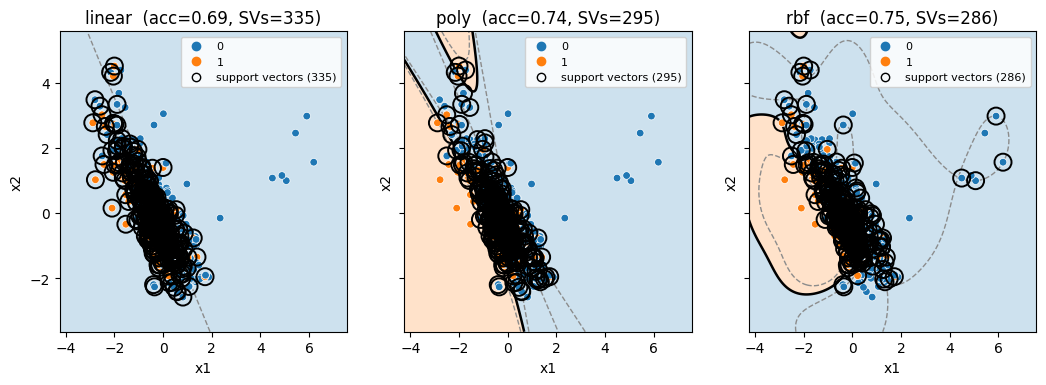


=== Tuned Gaussian Naive Bayes Diagnostics ===


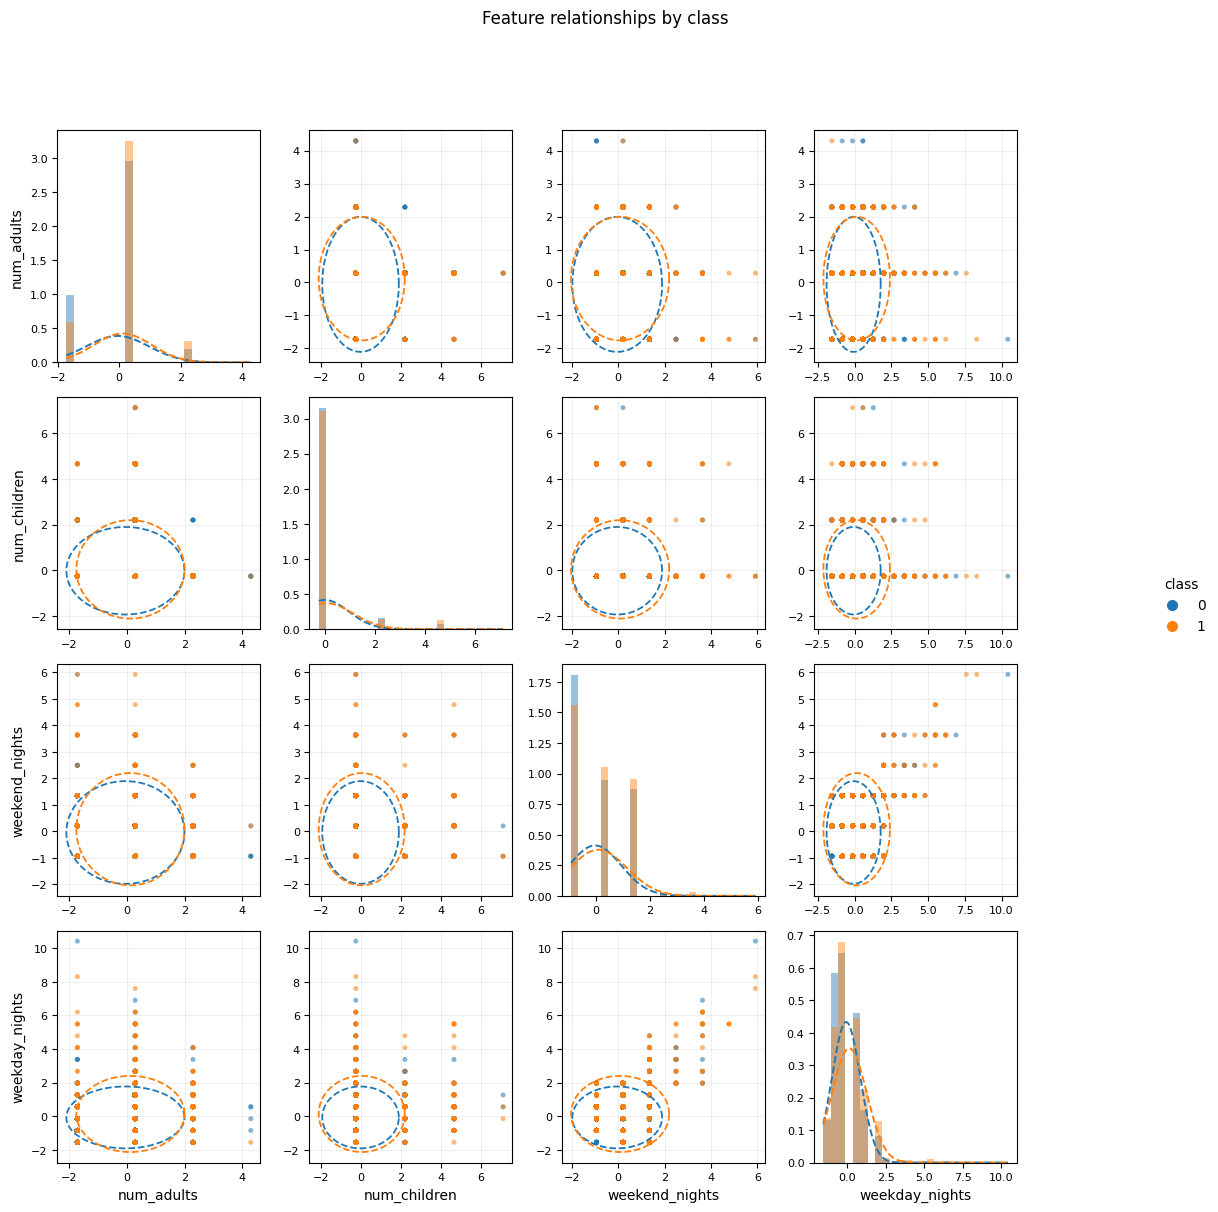

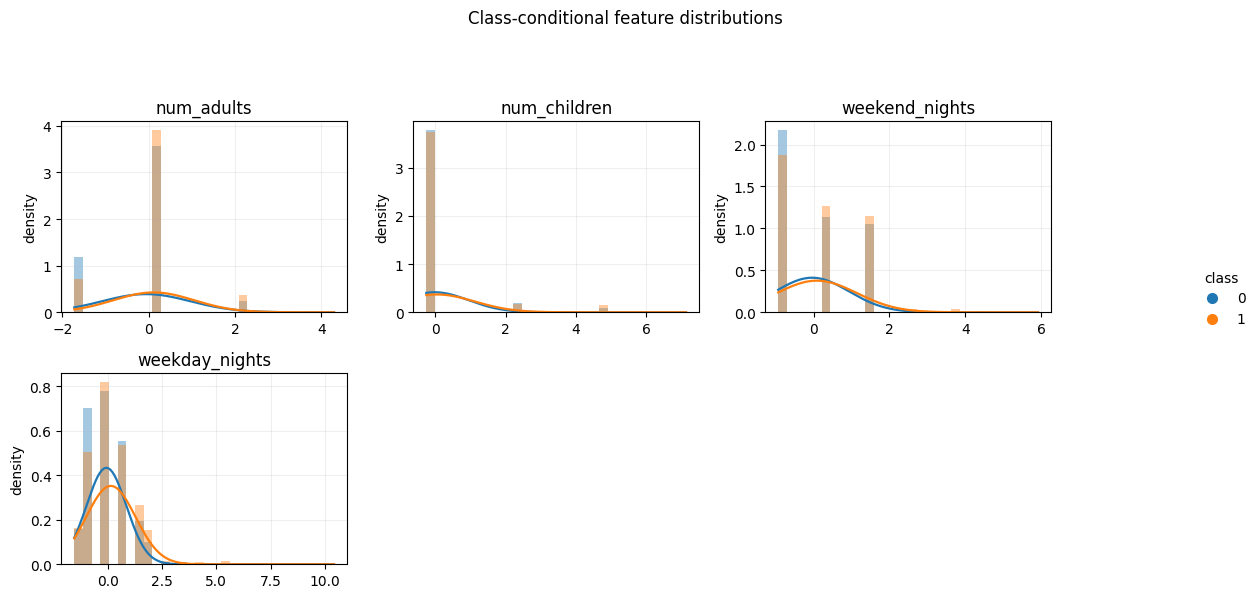

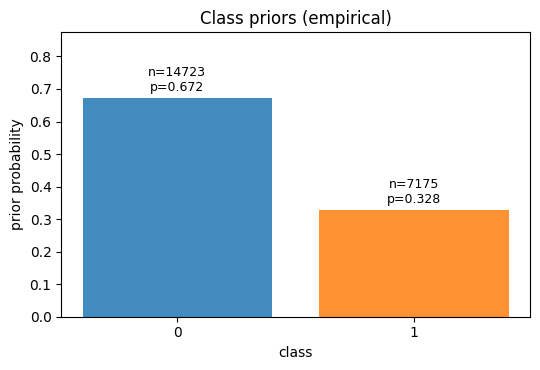

In [69]:
# 1. Export C4.5 Decision Tree text representation
print("=== Tuned C4.5 Decision Tree Structure ===")
tuned_dtl = tuned_models['dtl'].fit(X_train, y_train)
print(tuned_dtl.export_text(max_depth=3))

# 2. Plot SVC kernel comparison (using PCA downprojection to 2D for plotting)
print("\n=== Tuned SVC Kernel Comparison ===")
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=Settings.SEED)
X_train_pca = pca.fit_transform(X_train)
plot_kernel_comparison(X_train_pca[:500], y_train.iloc[:500], kernels=("linear", "poly", "rbf"),
                       C=optimal_params['svc']['C'], gamma=optimal_params['svc']['gamma'], show=True)

# 3. Plot GNB Feature Relationships & Class Distributions
print("\n=== Tuned Gaussian Naive Bayes Diagnostics ===")
tuned_gnb = tuned_models['gnb'].fit(X_train, y_train)
diagnostics = tuned_gnb.plot_all(X_val, y_val, features=feature_cols[:4])
plt.show()

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [73]:
knn_params = optimal_params['knn']
dtl_params = optimal_params['dtl'].copy()
svc_params = optimal_params['svc']
lr_params = optimal_params['lr']
gnb_params = optimal_params['gnb']

sklearn_knn = KNeighborsClassifier(
    n_neighbors=knn_params['n_neighbors'],
    weights=knn_params['weights'],
    metric=knn_params['metric']
)

sk_ccp_alpha = 0.0  # Default or small value since the tuned from-scratch model didn't use cost-complexity pruning
sklearn_dtl = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=dtl_params['max_depth'],
    ccp_alpha=sk_ccp_alpha,
    random_state=Settings.SEED
)

sklearn_svc = SVC(
    C=svc_params['C'],
    kernel=svc_params['kernel'],
    gamma=svc_params['gamma'],
    random_state=Settings.SEED
)

penalty_val = lr_params['penalty']
if penalty_val is None:
    penalty_val = 'none' if hasattr(LogisticRegression(), 'penalty') and 'none' in LogisticRegression.penalty.__doc__ else None

sklearn_lr = LogisticRegression(
    C=lr_params['C'],
    penalty=penalty_val,
    max_iter=lr_params['max_iter'],
    random_state=Settings.SEED
)

sklearn_gnb = GaussianNB(
    var_smoothing=gnb_params['var_smoothing']
)

sklearn_models = {
    'knn': sklearn_knn,
    'dtl': sklearn_dtl,
    'svc': sklearn_svc,
    'lr': sklearn_lr,
    'gnb': sklearn_gnb
}

custom_models = {
    'knn': tuned_models['knn'],
    'dtl': tuned_models['dtl'],
    'svc': tuned_models['svc'],
    'lr': tuned_models['lr'],
    'gnb': tuned_models['gnb']
}

# Evaluation comparison on the holdout validation set
results = []
for name in ['knn', 'dtl', 'svc', 'lr', 'gnb']:
    # Fit and evaluate Custom model
    clf_custom = clone(custom_models[name])
    if name == 'svc':
        # Use sub-train for SVC to prevent SMO convergence bottlenecks
        clf_custom.fit(X_train_sub, y_train_sub)
    else:
        clf_custom.fit(X_train, y_train)
    pred_custom = clf_custom.predict(X_val)
    score_custom = f1_score(y_val, pred_custom, average='macro')

    # Fit and evaluate Sklearn model
    clf_sklearn = clone(sklearn_models[name])
    if name == 'svc':
        clf_sklearn.fit(X_train_sub, y_train_sub)
    else:
        clf_sklearn.fit(X_train, y_train)
    pred_sklearn = clf_sklearn.predict(X_val)
    score_sklearn = f1_score(y_val, pred_sklearn, average='macro')

    results.append({
        'Model': name.upper(),
        'Custom F1 (Holdout)': score_custom,
        'Sklearn F1 (Holdout)': score_sklearn,
        'Difference': abs(score_custom - score_sklearn)
    })

comparison_table = pd.DataFrame(results)
print("=== Performance Comparison: From-Scratch vs. Scikit-Learn ===")
display(comparison_table)

=== Performance Comparison: From-Scratch vs. Scikit-Learn ===


,Model,Custom F1 (Holdout),Sklearn F1 (Holdout),Difference
0,KNN,0.829699,0.829699,0.000000
1,DTL,0.827053,0.830953,0.003899
2,SVC,0.776664,0.777022,0.000358
3,LR,0.749728,0.749465,0.000263
4,GNB,0.382910,0.382910,0.000000


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [72]:
import joblib

# Define paths for saving the custom tuned models
model_paths = {}
for name, model in tuned_models.items():
    # Ensure the model is fully fitted on the training set
    if name == 'svc':
        model.fit(X_train_sub, y_train_sub)
    else:
        model.fit(X_train, y_train)

    path = CFG.OUTPUT_DIR / f'{name}_v3.pkl'
    joblib.dump(model, path)
    model_paths[name] = path
    print(f"Saved {name.upper()} model to {path}")

print("\n--- Verifying Saved Models by Loading & Predicting ---")
# Load the models back and make sample predictions on validation data
loaded_models = {}
for name, path in model_paths.items():
    loaded_models[name] = joblib.load(path)
    preds = loaded_models[name].predict(X_val[:5])
    print(f"Loaded {name.upper()} Model. First 5 predictions: {preds}")

Saved KNN model to output/knn_v3.pkl
Saved DTL model to output/dtl_v3.pkl
Saved SVC model to output/svc_v3.pkl
Saved LR model to output/lr_v3.pkl
Saved GNB model to output/gnb_v3.pkl

--- Verifying Saved Models by Loading & Predicting ---
Loaded KNN Model. First 5 predictions: [0 1 0 0 1]
Loaded DTL Model. First 5 predictions: [0 1 0 1 1]
Loaded SVC Model. First 5 predictions: [0 1 0 1 0]
Loaded LR Model. First 5 predictions: [0 0 0 0 0]
Loaded GNB Model. First 5 predictions: [0 1 1 1 1]


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [75]:
# Select the best performing model (KNN from optimal_params)
best_model_name = 'knn'
best_model_params = optimal_params[best_model_name]

print(f"Best model identified: {best_model_name.upper()} with params: {best_model_params}")

# Instantiate the final model
final_model = KNeighborsClassifierFS(**best_model_params)

# Concatenate the already-preprocessed X_train and X_val to get the complete processed training set
print("Combining preprocessed train and validation splits...")
X_full_processed = pd.concat([X_train, X_val], axis=0)
y_full = pd.concat([y_train, y_val], axis=0)

print("Fitting the best model on the complete processed training data...")
final_model.fit(X_full_processed, y_full)

# Generate predictions on the preprocessed test set
print("Generating predictions on the test set...")
test_preds = final_model.predict(X_test)

# Construct the submission DataFrame
submission_df = pd.DataFrame({
    'id': test_df['id'],
    'is_canceled': test_preds
})

# Ensure the output directory exists and save the csv
submission_path = CFG.OUTPUT_DIR / 'submission.csv'
submission_df.to_csv(submission_path, index=False)

print(f"Submission file successfully saved to {submission_path}")
print(submission_df.head())
print(f"Submission shape: {submission_df.shape}")

Best model identified: KNN with params: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Combining preprocessed train and validation splits...
Fitting the best model on the complete processed training data...
Generating predictions on the test set...
Submission file successfully saved to output/submission.csv
         id  is_canceled
0  5cb6f473            1
1  c06b4ab3            1
2  22bf3fc3            0
3  25408a48            0
4  621586b6            0
Submission shape: (6844, 2)


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.